# UCU AI HW2 — Multiple Object Video Detection (VisDrone drone clips)

Experiment log for the [Kaggle competition](https://www.kaggle.com/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026): detect 8 object classes in drone video frames. Everything here ran on a Colab T4 with outputs kept as executed.

| Part | What it does | Rubric item |
|---|---|---|
| 0 Setup | download data, check GPU, mount Drive | — |
| 1 Data | annotation statistics, train/val split check, label visualisation, pilot sample | Data understanding |
| 2 Pilots | one-epoch Faster R-CNN and YOLO26n on 271 frames | baselines |
| 3 Faster R-CNN | longer training on 4,868 frames, full-validation scores | two-stage |
| 4 RetinaNet | same sample, early stopping | one-stage, anchor-based |
| 5 YOLO26n and RT-DETR-L | YOLO-format data, training, COCO-metric scoring | anchor-free, query-based |
| 6 Comparison | four-model chart, visual check, class-wise AP, what is left on Drive | summary |
| 7 Test predictions | RT-DETR-L submission file and its format checks | submission |

**How to read this file**
- It was reorganised after the runs: cells were reordered, duplicated and debugging cells removed, long logs trimmed (marked `[... trimmed ...]`). Nothing was re-executed.
- It does **not** run top to bottom. Part 4 resumes a run whose setup cells are not in this file, and Part 5 uses an evaluation helper that was defined in a lost cell. The reproducible pipeline is in `scripts/`.
- All scores use COCO metrics on the 2,846 validation frames (7 clips), with ignored regions kept as `iscrowd`.

## Part 0 — Setup
Download the competition data, check the GPU, mount Google Drive for checkpoints.

In [ ]:
import kagglehub
# You may need to re-run this cell after logging in.
kagglehub.login()
path = kagglehub.competition_download('multiple-object-video-detection-hw-2-ucu-ai-2026')

100%|██████████| 9.88G/9.88G [01:50<00:00, 96.4MB/s]

Extracting files...


Kaggle credentials set.
Kaggle credentials successfully validated.


### Check the runtime

PyTorch runs neural networks. This check confirms CUDA and T4 GPU availability; a GPU can speed up training.

In [58]:
import torch
print('torch:', torch.__version__)
print('cuda available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('gpu:', torch.cuda.get_device_name(0))

torch: 2.11.0+cu130
cuda available: True
gpu: Tesla T4


### Locate the data files

Use Python paths to find the downloaded images and annotation files.

In [ ]:
from pathlib import Path; root = Path(path); print('download path:', root); print('exists:', root.exists()); print('top-level:', [(p.name, 'dir' if p.is_dir() else f'{p.stat().st_size:,} bytes') for p in sorted(root.iterdir())[:30]]); print('annotation files:', [str(p.relative_to(root)) for p in root.rglob('annotations_coco.json')])

download path: /root/.cache/kagglehub/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
exists: True
top-level: [('test', 'dir'), ('test_images.csv', '271,270 bytes'), ('train', 'dir'), ('val', 'dir')]
annotation files: ['train/annotations_coco.json', 'val/annotations_coco.json']


### Save training outputs

Store checkpoints and results in Google Drive, then confirm the GPU and required tools.

In [ ]:
from google.colab import drive
from pathlib import Path
import importlib.util, shutil, torch

drive.mount('/content/drive')
output_dir = Path('/content/drive/MyDrive/UCU_AI_HW2')
checkpoint_dir = output_dir / 'checkpoints'
results_dir = output_dir / 'results'
checkpoint_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), 'CUDA GPU is required for this run'
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)
print('TorchVision:', importlib.util.find_spec('torchvision') is not None)
print('Ultralytics:', importlib.util.find_spec('ultralytics') is not None)
print('pycocotools:', importlib.util.find_spec('pycocotools') is not None)
print('saved outputs:', output_dir)
print('Drive free space (GB):', round(shutil.disk_usage(output_dir).free / 1e9, 1))

Mounted at /content/drive
GPU: Tesla T4
PyTorch: 2.11.0+cu130
TorchVision: True
Ultralytics: False
pycocotools: True
saved outputs: /content/drive/MyDrive/UCU_AI_HW2
Drive free space (GB): 15.9


In [ ]:
import subprocess, sys

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
from ultralytics import RTDETR, YOLO
print('Ultralytics model tools ready:', YOLO.__name__, RTDETR.__name__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics model tools ready: YOLO RTDETR


## Part 1 — Data understanding
Annotation counts, a train/validation clip-overlap check, label visualisation, and the frame sample used for pilot runs. Fuller statistics are in `scripts/01_eda.py`.

### Summarize the annotations

Count the frames, sequences, objects, and crowd regions. Check that train and validation sequences do not overlap.

In [ ]:
import csv, json
from collections import Counter
splits = {s: json.loads((root / s / 'annotations_coco.json').read_text()) for s in ('train', 'val')}
stats = {s: (len(c['images']), len({i['video'] for i in c['images']}), len(c['annotations']), sum(bool(a.get('iscrowd', 0)) for a in c['annotations']), dict(Counter(a['category_id'] for a in c['annotations'] if not a.get('iscrowd', 0))), (root / s / c['images'][0]['file_name']).is_file()) for s, c in splits.items()}
print('split: frames, sequences, annotations, crowd, non-crowd class counts, sample image exists')
print(stats)
print('train/validation sequence overlap:', {i['video'] for i in splits['train']['images']} & {i['video'] for i in splits['val']['images']})
test = list(csv.DictReader((root / 'test_images.csv').open(newline='')))
print('test rows, unique clips, columns:', len(test), len({r['clip'] for r in test}), list(test[0]))
print('sample test image exists:', (root / test[0]['file_name']).is_file(), test[0]['file_name'])

split: frames, sequences, annotations, crowd, non-crowd class counts, sample image exists
{'train': (24201, 56, 1616260, 510744, {1: 328701, 6: 41349, 8: 102819, 2: 40255, 3: 505301, 4: 46940, 5: 30498, 7: 9653}, True), 'val': (2846, 7, 146092, 31960, {1: 50312, 8: 12025, 2: 6022, 3: 31821, 6: 5487, 4: 6842, 5: 1359, 7: 264}, True)}
train/validation sequence overlap: set()
test rows, unique clips, columns: 3811 48 ['image_id', 'file_name', 'clip', 'frame', 'width', 'height']
sample test image exists: True test/images/clip_001/0000001.jpg


### Visualize labeled frames

Show object labels and crowd regions on a sample image. These boxes are ground-truth annotations.

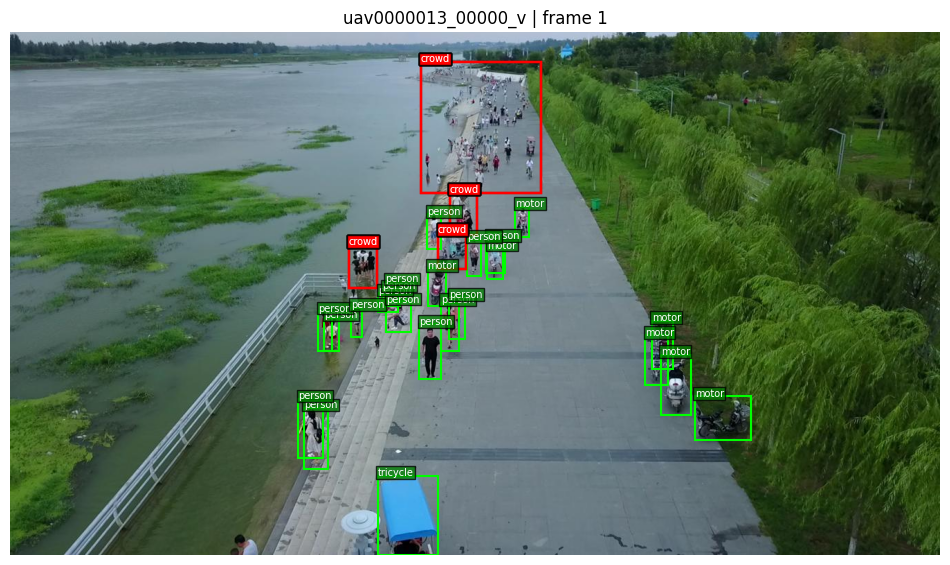

Boxes: 55 | crowd boxes: 32


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

train_labels = splits['train']
crowd_ids = {a['image_id'] for a in train_labels['annotations'] if a.get('iscrowd', 0)}
object_ids = {a['image_id'] for a in train_labels['annotations'] if not a.get('iscrowd', 0)}
mixed_ids = crowd_ids & object_ids
example_id = min(mixed_ids or crowd_ids)
example = next(im for im in train_labels['images'] if im['id'] == example_id)
boxes = [a for a in train_labels['annotations'] if a['image_id'] == example_id]
names = {c['id']: c['name'] for c in train_labels['categories']}
frame = Image.open(root / 'train' / example['file_name']).convert('RGB')
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(frame)
[ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor='red' if a.get('iscrowd', 0) else 'lime', linewidth=1.5)) for a in boxes for x, y, w, h in [a['bbox']]]
[ax.text(x, y, 'crowd' if a.get('iscrowd', 0) else names[a['category_id']], color='white', fontsize=7, bbox={'facecolor': 'red' if a.get('iscrowd', 0) else 'green', 'alpha': 0.75, 'pad': 1}) for a in boxes for x, y, w, h in [a['bbox']]]
ax.set_title(f"{example['video']} | frame {example['frame_id']}")
ax.axis('off')
plt.show()
print(f"Boxes: {len(boxes)} | crowd boxes: {sum(bool(a.get('iscrowd', 0)) for a in boxes)}")

### Sample frames for a pilot run

We will sample one frame in every 100 from each video. This keeps the first training run small while representing every video. Validation samples come only from held-out videos.

In [ ]:
from collections import defaultdict

def sample_frames(split, gap=100):
    videos = defaultdict(list)
    for image in split['images']:
        videos[image['video']].append(image)
    sample = []
    for frames in videos.values():
        frames.sort(key=lambda image: image['frame_id'])
        sample.extend(frames[::gap])
    return sample

train_sample = sample_frames(splits['train'])
val_sample = sample_frames(splits['val'])
train_videos = {image['video'] for image in splits['train']['images']}
val_videos = {image['video'] for image in splits['val']['images']}
assert train_videos.isdisjoint(val_videos), 'Train and validation videos must be separate'

print(f'Train sample: {len(train_sample)} frames from {len(train_videos)} videos')
print(f'Validation sample: {len(val_sample)} frames from {len(val_videos)} videos')
print('First training frame:', train_sample[0]['file_name'])

Train sample: 271 frames from 56 videos
Validation sample: 31 frames from 7 videos
First training frame: images/uav0000013_00000_v/0000001.jpg


### Prepare a small training batch

A detector needs each image as a tensor and each box as `[x_min, y_min, x_max, y_max]`, with its class ID. This check loads two sampled frames. The training targets omit `iscrowd` boxes, but those areas are not masked from the loss.

In [ ]:
from collections import defaultdict
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import pil_to_tensor
from PIL import Image
import torch

annotations_by_image = defaultdict(list)
for annotation in splits['train']['annotations']:
    if not annotation.get('iscrowd', 0):
        annotations_by_image[annotation['image_id']].append(annotation)

class VideoFrameDataset(Dataset):
    def __init__(self, image_info):
        self.image_info = image_info

    def __len__(self):
        return len(self.image_info)

    def __getitem__(self, index):
        info = self.image_info[index]
        with Image.open(root / 'train' / info['file_name']) as source:
            image = pil_to_tensor(source.convert('RGB')).float() / 255
        boxes, labels = [], []
        for annotation in annotations_by_image[info['id']]:
            x, y, width, height = annotation['bbox']
            if width > 0 and height > 0:
                boxes.append([x, y, x + width, y + height])
                labels.append(annotation['category_id'])
        target = {
            'boxes': torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            'labels': torch.tensor(labels, dtype=torch.int64),
        }
        return image, target

labeled_sample = [info for info in train_sample if annotations_by_image[info['id']]][:2]
assert len(labeled_sample) == 2, 'Need two sampled frames with labeled objects'
loader = DataLoader(VideoFrameDataset(labeled_sample), batch_size=2, collate_fn=lambda batch: tuple(zip(*batch)))
images, targets = next(iter(loader))
assert len(images) == 2
assert all(target['boxes'].shape == (len(target['labels']), 4) for target in targets)
assert all(torch.isfinite(target['boxes']).all() for target in targets)
print('Image shapes (C, H, W):', [tuple(image.shape) for image in images])
print('Objects per image:', [len(target['labels']) for target in targets])
print('Class IDs:', sorted(set(torch.cat([target['labels'] for target in targets]).tolist())))

Image shapes (C, H, W): [(3, 756, 1344), (3, 756, 1344)]
Objects per image: [23, 30]
Class IDs: [1, 2, 6, 8]


## Part 2 — Pilot runs
One epoch on 271 frames (one in 100 per clip) for Faster R-CNN and YOLO26n, both scored on all 2,846 validation frames. These are quick sanity baselines, not final models.

### Detector experiments

### Build the Faster R-CNN baseline

Faster R-CNN is a two-stage detector: it first proposes object regions, then classifies them. We use COCO pretrained weights as a starting point and replace the classifier for the eight assignment classes.

In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn(weights=weights, weights_backbone=None)
features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(features, 9)  # 8 classes plus background
model = model.to(torch.device('cuda'))

assert model.roi_heads.box_predictor.cls_score.out_features == 9
print('Model: Faster R-CNN ResNet-50 FPN')
print('Device:', next(model.parameters()).device)
print('Outputs:', model.roi_heads.box_predictor.cls_score.out_features, '(background + 8 classes)')

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 160MB/s]


Model: Faster R-CNN ResNet-50 FPN
Device: cuda:0
Outputs: 9 (background + 8 classes)


### Train the baseline

Train one epoch on the sampled training frames and save the checkpoint to Drive. Training loss shows learning progress; it is not a validation score.

In [ ]:
import time
import random
import numpy as np
from torch.utils.data import DataLoader

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

train_frames = [info for info in train_sample if annotations_by_image[info['id']]]
train_loader = DataLoader(
    VideoFrameDataset(train_frames), batch_size=1, shuffle=True,
    collate_fn=lambda batch: tuple(zip(*batch))
)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
checkpoint_path = checkpoint_dir / 'fasterrcnn_pilot.pt'
model.train()
loss_history = []
start_time = time.perf_counter()

for step, (batch_images, batch_targets) in enumerate(train_loader, start=1):
    batch_images = [image.to('cuda') for image in batch_images]
    batch_targets = [
        {key: value.to('cuda') for key, value in target.items()}
        for target in batch_targets
    ]
    loss = sum(model(batch_images, batch_targets).values())
    assert torch.isfinite(loss), f'Non-finite loss at step {step}'
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

    if step % 50 == 0:
        torch.save({
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'epoch': 1, 'step': step, 'seed': seed, 'stride': 100,
        }, checkpoint_path)
        print(f'step {step}/{len(train_loader)} | mean loss: {np.mean(loss_history[-50:]):.4f}', flush=True)

torch.save({
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'epoch': 1, 'step': len(train_loader), 'seed': seed, 'stride': 100,
}, checkpoint_path)
print(f'Finished {len(train_loader)} steps in {(time.perf_counter() - start_time) / 60:.1f} min')
print(f'Mean training loss: {np.mean(loss_history):.4f}')
print(f'Checkpoint saved: {checkpoint_path}')

step 50/271 | mean loss: 1.6069
step 100/271 | mean loss: 1.4846
step 150/271 | mean loss: 1.3557
step 200/271 | mean loss: 1.2926
step 250/271 | mean loss: 1.2862
Finished 271 steps in 2.5 min
Mean training loss: 1.3839
Checkpoint saved: /content/drive/MyDrive/UCU_AI_HW2/checkpoints/fasterrcnn_pilot.pt


### Validate on all held-out frames

The pilot check used only a small sample. Here we score every frame in the seven held-out videos. This gives us a steadier baseline before deciding how much training to run.

In [ ]:
import json, time
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

val_images = splits['val']['images']
val_path = root / 'val'
val_data = json.loads((val_path / 'annotations_coco.json').read_text())
val_ids = [info['id'] for info in val_images]
val_videos = {info['file_name'].split('/')[1] for info in val_images}
assert len(val_images) == 2846 and len(val_videos) == 7

model.eval()
predictions, inference_seconds = [], 0.0
for index, info in enumerate(val_images, start=1):
    with Image.open(val_path / info['file_name']) as image:
        tensor = pil_to_tensor(image.convert('RGB')).float().div_(255).to('cuda')
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.inference_mode():
        output = model([tensor])[0]
    torch.cuda.synchronize()
    inference_seconds += time.perf_counter() - start
    boxes = output['boxes'].cpu().tolist()
    labels = output['labels'].cpu().tolist()
    scores = output['scores'].cpu().tolist()
    for box, label, score in zip(boxes, labels, scores):
        x1, y1, x2, y2 = box
        predictions.append({
            'image_id': info['id'], 'category_id': int(label),
            'bbox': [x1, y1, x2 - x1, y2 - y1], 'score': float(score)
        })
    if index % 250 == 0 or index == len(val_images):
        print(f'Processed {index}/{len(val_images)} validation frames', flush=True)

coco_gt = COCO()
coco_gt.dataset = val_data
coco_gt.createIndex()
coco_dt = coco_gt.loadRes(predictions)
evaluation = COCOeval(coco_gt, coco_dt, 'bbox')
evaluation.params.imgIds = val_ids
evaluation.evaluate()
evaluation.accumulate()
evaluation.summarize()
metrics = {
    'model': 'Faster R-CNN ResNet-50 FPN',
    'validation_images': len(val_images),
    'validation_videos': len(val_videos),
    'mAP': float(evaluation.stats[0]),
    'AP50': float(evaluation.stats[1]),
    'AP_small': float(evaluation.stats[3]),
    'mean_inference_ms_per_image': inference_seconds / len(val_images) * 1000
}
metric_path = results_dir / 'fasterrcnn_fullval_metrics.json'
metric_path.write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))
print('Saved:', metric_path)

Processed 250/2846 validation frames
Processed 500/2846 validation frames
Processed 750/2846 validation frames
Processed 1000/2846 validation frames
Processed 1250/2846 validation frames
Processed 1500/2846 validation frames
Processed 1750/2846 validation frames
Processed 2000/2846 validation frames
Processed 2250/2846 validation frames
Processed 2500/2846 validation frames
Processed 2750/2846 validation frames
Processed 2846/2846 validation frames
creating index...
index created!
Loading and preparing results...
DONE (t=0.30s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=78.27s).
Accumulating evaluation results...
DONE (t=3.28s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.081
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.179
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.063
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | max

### Baseline result

The model trained for one epoch on 271 sampled training frames. It was evaluated on all 2,846 frames from seven held-out videos. Training loss shows learning progress; validation AP measures detection quality.

| Validation metric | Score | What it measures |
|---|---:|---|
| mAP | 0.081 | Average precision across IoU thresholds 0.50 to 0.95 |
| AP50 | 0.179 | Average precision at IoU 0.50 |
| AP_small | 0.049 | Average precision for small objects |
| Inference time | 199 ms/image | Time for one model prediction |

This is the first baseline. The pilot sample is much smaller than the full training set.

### Compare the validation scores

Higher average precision means more accurate box and class predictions. The bars use the same 0–1 scale.

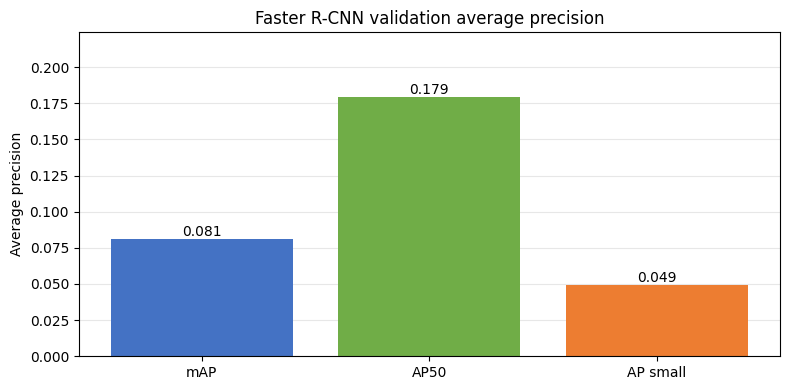

In [ ]:
import json
import matplotlib.pyplot as plt

metric_path = results_dir / 'fasterrcnn_fullval_metrics.json'
summary = json.loads(metric_path.read_text())
labels = ['mAP', 'AP50', 'AP small']
scores = [summary['mAP'], summary['AP50'], summary['AP_small']]
assert len(scores) == 3 and all(0 <= score <= 1 for score in scores)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, scores, color=['#4472C4', '#70AD47', '#ED7D31'])
ax.set_title('Faster R-CNN validation average precision')
ax.set_ylabel('Average precision')
ax.set_ylim(0, max(scores) * 1.25)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
for bar, score in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width() / 2, score, f'{score:.3f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

### Example detections

Green boxes show annotated objects. Blue boxes show model predictions with score at least 0.30 (up to 10, for readability). This example helps inspect errors; it is not a separate metric.

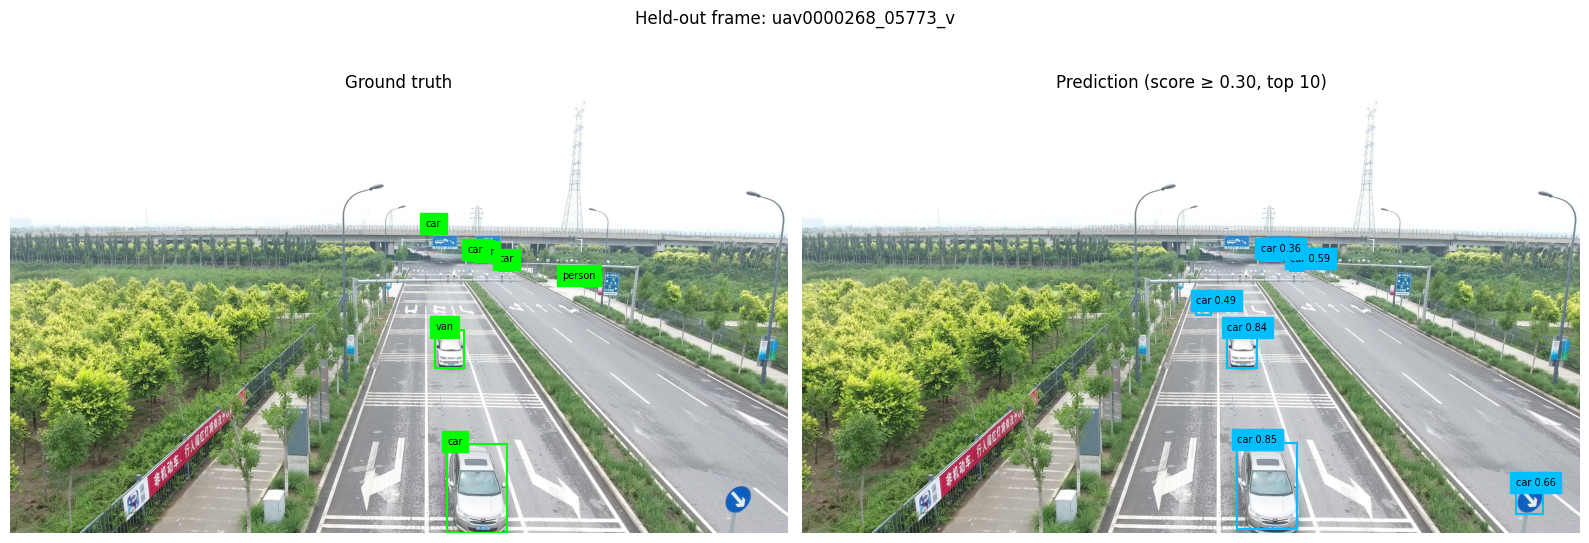

In [ ]:
from collections import defaultdict
from matplotlib.patches import Rectangle

class_names = {category['id']: category['name'] for category in val_data['categories']}
ground_truth = defaultdict(list)
for annotation in val_data['annotations']:
    if not annotation.get('iscrowd', 0):
        ground_truth[annotation['image_id']].append(annotation)
candidates = [info for info in val_images if 1 <= len(ground_truth[info['id']]) <= 8]
assert candidates, 'No validation frame has 1–8 labeled objects'
info = candidates[len(candidates) // 2]
image_predictions = sorted(
    (item for item in predictions if item['image_id'] == info['id'] and item['score'] >= 0.30),
    key=lambda item: item['score'], reverse=True
)[:10]
with Image.open(val_path / info['file_name']) as source:
    image = source.convert('RGB')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(image)
axes[0].set_title('Ground truth')
for item in ground_truth[info['id']]:
    x, y, width, height = item['bbox']
    axes[0].add_patch(Rectangle((x, y), width, height, fill=False, edgecolor='lime', linewidth=1.5))
    axes[0].text(x, y, class_names.get(item['category_id'], str(item['category_id'])),
                 color='black', fontsize=7, backgroundcolor='lime')
axes[1].imshow(image)
axes[1].set_title('Prediction (score ≥ 0.30, top 10)')
for item in image_predictions:
    x, y, width, height = item['bbox']
    axes[1].add_patch(Rectangle((x, y), width, height, fill=False, edgecolor='deepskyblue', linewidth=1.5))
    label = class_names.get(item['category_id'], str(item['category_id']))
    axes[1].text(x, y, f'{label} {item["score"]:.2f}', color='black',
                 fontsize=7, backgroundcolor='deepskyblue')
if not image_predictions:
    axes[1].text(0.5, 0.5, 'No predictions above the score threshold',
                 transform=axes[1].transAxes, ha='center', color='white',
                 bbox=dict(facecolor='black', alpha=0.7))
for axis in axes:
    axis.axis('off')
fig.suptitle(f"Held-out frame: {info['file_name'].split('/')[1]}")
plt.tight_layout()
plt.show()

### YOLO pilot

YOLO is a one-stage detector: it predicts object boxes and classes in one pass. We will fine-tune a pretrained YOLO26n model for one epoch on the same 271 sampled training frames. We will compare it on the same 2,846 held-out frames.

#### Prepare YOLO labels

YOLO stores each box as a class number and normalized center, width, and height. Crowd boxes are omitted because this format has no crowd-ignore flag. Final scoring will use the original COCO annotations, including crowd flags.

In [ ]:
import json, os
from collections import defaultdict
from pathlib import Path
import ultralytics

yolo_dir = Path('/content/UCU_AI_HW2/yolo_pilot')
yolo_dir.mkdir(parents=True, exist_ok=True)
train_data = json.loads((root / 'train' / 'annotations_coco.json').read_text())
class_categories = sorted(val_data['categories'], key=lambda category: category['id'])
assert len(class_categories) == 8
class_to_index = {category['id']: index for index, category in enumerate(class_categories)}
class_names = [category['name'] for category in class_categories]

def write_yolo_split(split_name, selected_images, coco_data):
    selected_ids = {image['id'] for image in selected_images}
    image_info = {image['id']: image for image in coco_data['images'] if image['id'] in selected_ids}
    annotations_by_image = defaultdict(list)
    for annotation in coco_data['annotations']:
        if annotation['image_id'] in selected_ids and not annotation.get('iscrowd', 0):
            annotations_by_image[annotation['image_id']].append(annotation)
    for image_id in selected_ids:
        info = image_info[image_id]
        relative = Path(info['file_name'])
        if relative.parts[0] == 'images':
            relative = Path(*relative.parts[1:])
        source = (root / split_name / info['file_name']).resolve()
        image_link = yolo_dir / 'images' / split_name / relative
        label_path = yolo_dir / 'labels' / split_name / relative.with_suffix('.txt')
        image_link.parent.mkdir(parents=True, exist_ok=True)
        label_path.parent.mkdir(parents=True, exist_ok=True)
        if not image_link.exists():
            image_link.symlink_to(source)
        assert image_link.resolve() == source and source.is_file()
        width, height = info['width'], info['height']
        lines = []
        for annotation in annotations_by_image[image_id]:
            x, y, box_width, box_height = annotation['bbox']
            assert box_width > 0 and box_height > 0
            center_x = (x + box_width / 2) / width
            center_y = (y + box_height / 2) / height
            normalized_width, normalized_height = box_width / width, box_height / height
            assert all(0 <= value <= 1 for value in (center_x, center_y, normalized_width, normalized_height))
            lines.append(f"{class_to_index[annotation['category_id']]} {center_x:.6f} {center_y:.6f} {normalized_width:.6f} {normalized_height:.6f}")
        label_path.write_text('\n'.join(lines))
    return len(selected_ids)

train_count = write_yolo_split('train', train_sample, train_data)
val_count = write_yolo_split('val', val_images, val_data)
data_yaml = yolo_dir / 'data.yaml'
data_yaml.write_text(
    f"path: {yolo_dir}\ntrain: images/train\nval: images/val\nnames: {json.dumps(class_names)}\n"
)
assert train_count == 271 and val_count == 2846
print('Ultralytics:', ultralytics.__version__)
print('YOLO pilot frames:', train_count, '| validation frames:', val_count)
print('Classes (YOLO IDs 0-7):', class_names)
print('Dataset config:', data_yaml)

Ultralytics: 8.4.187
YOLO pilot frames: 271 | validation frames: 2846
Classes (YOLO IDs 0-7): ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']
Dataset config: /content/UCU_AI_HW2/yolo_pilot/data.yaml


#### Train the YOLO pilot

Fine-tune the pretrained model for one epoch on the 271 sampled training frames. Ultralytics also prints a validation score using converted labels, which omit crowd regions. For comparison, we score the saved model on the original COCO annotations, including crowd flags. The checkpoint is saved to Drive.

In [ ]:
import time
from ultralytics import YOLO

del model
torch.cuda.empty_cache()
yolo_model = YOLO('yolo26n.pt')
yolo_start = time.perf_counter()
yolo_model.train(
    data=str(data_yaml), epochs=1, imgsz=640, batch=16,
    device=0, workers=2, seed=42, close_mosaic=0,
    project=str(output_dir / 'runs'), name='yolo26n_pilot',
    exist_ok=True, val=False, plots=False, verbose=True
)
yolo_checkpoint = output_dir / 'runs' / 'yolo26n_pilot' / 'weights' / 'last.pt'
assert yolo_checkpoint.is_file(), f'Missing checkpoint: {yolo_checkpoint}'
print(f'Training time: {(time.perf_counter() - yolo_start) / 60:.1f} min')
print('Checkpoint saved:', yolo_checkpoint)

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/UCU_AI_HW2/yolo_pilot/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_pilot, nbs=64, nms=None, opset=None, optimi

#### Score YOLO on the held-out videos

Ultralytics reports a score using converted labels that omit crowd regions. For the model comparison, run YOLO on the same 2,846 frames and score its boxes against the original COCO annotations, including crowd flags.

In [ ]:
import gc, json, time
from pathlib import Path
import torch
from google.colab import drive
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

drive.mount('/content/drive', force_remount=False)
root = Path('/root/.cache/kagglehub/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026')
val_path, val_json = root / 'val', root / 'val/annotations_coco.json'
output_dir = Path('/content/drive/MyDrive/UCU_AI_HW2')
results_dir = output_dir / 'results'
checkpoint = output_dir / 'runs/yolo26n_pilot/weights/last.pt'
assert val_json.is_file() and checkpoint.is_file() and torch.cuda.is_available()
coco_gt = COCO(str(val_json))
val_images = coco_gt.dataset['images']
assert len(val_images) == 2846
val_paths = [str(val_path / image['file_name']) for image in val_images]
class_categories = sorted(coco_gt.dataset['categories'], key=lambda c: c['id'])
yolo_to_coco = {i: category['id'] for i, category in enumerate(class_categories)}
print('Ground truth loaded; starting chunked inference.', flush=True)
torch.cuda.empty_cache()
yolo_model = YOLO(str(checkpoint))
predictions, inference_ms = [], []
start = time.perf_counter()
for first in range(0, len(val_images), 16):
    stop = min(first + 16, len(val_images))
    batch_paths = val_paths[first:stop]
    batch_images = val_images[first:stop]
    for image, result in zip(batch_images, yolo_model.predict(
        source=batch_paths, imgsz=640, batch=1, device=0, conf=0.001,
        max_det=100, stream=True, verbose=False
    )):
        assert Path(result.path).name == Path(image['file_name']).name
        inference_ms.append(result.speed['inference'])
        if result.boxes is not None:
            for box, score, label in zip(result.boxes.xyxy.cpu().tolist(),
                                         result.boxes.conf.cpu().tolist(),
                                         result.boxes.cls.int().cpu().tolist()):
                x1, y1, x2, y2 = box
                predictions.append({'image_id': image['id'], 'category_id': yolo_to_coco[label],
                                    'bbox': [x1, y1, x2-x1, y2-y1], 'score': score})
    if stop % 256 == 0 or stop == len(val_images):
        print(f'Processed {stop}/{len(val_images)} frames; predictions: {len(predictions):,}', flush=True)
    del batch_paths, batch_images
    gc.collect()
wall_seconds = time.perf_counter() - start
print(f'Inference complete: {len(predictions):,} detections, {wall_seconds/60:.1f} min', flush=True)
coco_dt = coco_gt.loadRes(predictions)
coco_eval = COCOeval(coco_gt, coco_dt, 'bbox')
coco_eval.params.imgIds = [image['id'] for image in val_images]
coco_eval.evaluate(); coco_eval.accumulate(); coco_eval.summarize()
metrics = {
    'model': 'YOLO26n', 'training_frames': 271, 'training_epochs': 1,
    'validation_frames': len(val_images), 'validation_videos': 7,
    'mAP': float(coco_eval.stats[0]), 'AP50': float(coco_eval.stats[1]),
    'AP_small': float(coco_eval.stats[3]),
    'mean_inference_ms_per_image': float(sum(inference_ms) / len(inference_ms)),
    'measured_wall_seconds': wall_seconds, 'prediction_count': len(predictions),
    'evaluation': 'Original COCO validation annotations, including crowd flags'
}
(results_dir / 'yolo26n_fullval_metrics.json').write_text(json.dumps(metrics, indent=2))
(results_dir / 'yolo26n_fullval_predictions.json').write_text(json.dumps(predictions))
print(json.dumps(metrics, indent=2))
print('Saved to:', results_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
loading annotations into memory...
Done (t=0.53s)
creating index...
index created!
Ground truth loaded; starting chunked inference.
Processed 256/2846 frames; predictions: 25,600
Processed 512/2846 frames; predictions: 51,200
Processed 768/2846 frames; predictions: 76,800
Processed 1024/2846 frames; predictions: 102,400
Processed 1280/2846 frames; predictions: 128,000
Processed 1536/2846 frames; predictions: 153,600
Processed 1792/2846 frames; predictions: 179,200
Processed 2048/2846 frames; predictions: 204,800
Processed 2304/2846 frames; predictions: 230,349
Processed 2560/2846 frames; predictions: 255,898
Processed 2816/2846 frames; predictions: 281,498
Processed 2846/2846 frames; predictions: 284,498
Inference complete: 284,498 detections, 2.9 min
Loading and preparing results...
DONE (t=0.67s)
creating index...
index created!
Running per image evaluation

### Pilot model comparison

Both detectors trained for one epoch on the same 271 sampled training frames. We scored both on all 2,846 frames from the same seven held-out videos with the original COCO annotations, including crowd regions.

| Model | mAP | AP50 | AP small | Mean inference time |
|---|---:|---:|---:|---:|
| Faster R-CNN | 0.0811 | 0.1792 | 0.0490 | 199 ms/image |
| YOLO26n | 0.0466 | 0.0970 | 0.0086 | 3.5 ms/image |

In this pilot, Faster R-CNN scored higher on all three accuracy measures. YOLO26n was much faster. These are early results from one epoch on a small sample, so they guide the next training run rather than establish the final ranking. Timing is approximate because the two frameworks measure inference differently.

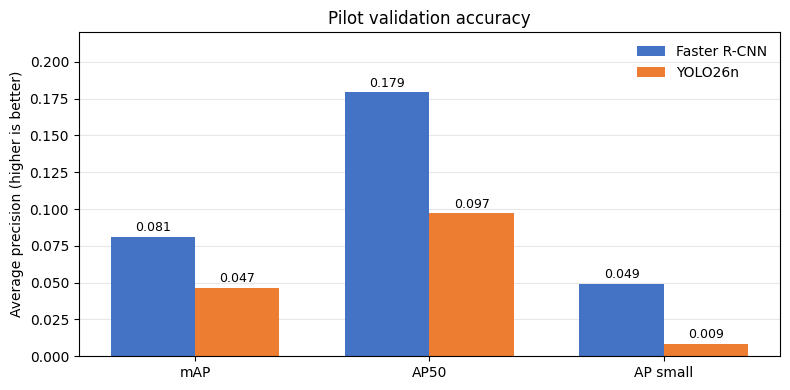

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np

faster = json.loads((results_dir / 'fasterrcnn_fullval_metrics.json').read_text())
yolo = json.loads((results_dir / 'yolo26n_fullval_metrics.json').read_text())
metrics = ['mAP', 'AP50', 'AP_small']
labels = ['mAP', 'AP50', 'AP small']
x = np.arange(len(metrics))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4))
bars_faster = ax.bar(x - width/2, [faster[key] for key in metrics], width,
                     label='Faster R-CNN', color='#4472C4')
bars_yolo = ax.bar(x + width/2, [yolo[key] for key in metrics], width,
                   label='YOLO26n', color='#ED7D31')
ax.set_title('Pilot validation accuracy')
ax.set_ylabel('Average precision (higher is better)')
ax.set_xticks(x, labels)
ax.set_ylim(0, 0.22)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
for bars in (bars_faster, bars_yolo):
    ax.bar_label(bars, fmt='%.3f', padding=2, fontsize=9)
plt.tight_layout()
plt.show()

### Pilot conclusion

Faster R-CNN is the stronger choice for the next accuracy-focused training run: its mAP was 0.081, compared with 0.047 for YOLO26n, and its AP small was 0.049 versus 0.009. YOLO26n remains a useful speed reference. Since each model trained for only one epoch on 271 frames, these pilot results are preliminary.

## Part 3 — Faster R-CNN on a larger sample
Training continues on 4,868 frames (every 5th frame of each of the 56 training clips), checking a fixed 219-frame validation sample every 1,000 steps. The run was stopped by hand at step 3,755, so the final checkpoint comes from the saved state, not from early stopping.

### Time-bounded Faster R-CNN training

The training split contains 24,201 frames from 56 videos. A full pass takes longer than the one-hour runtime limit, so this run uses a fixed sample spread across all training videos.

We will check mAP on the same held-out sample every 1,000 steps. Training stops after three checks without a meaningful gain, or after 3,000 additional steps. The best checkpoint is saved to Google Drive. We then score that checkpoint on all 2,846 validation frames. The full validation result is the reported score.

In [ ]:
import gc, importlib.util, subprocess, sys
from collections import defaultdict
from pathlib import Path
import psutil, torch, ijson
from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms.functional import pil_to_tensor

root = Path('/root/.cache/kagglehub/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026')
train_json = root / 'train/annotations_coco.json'
checkpoint_dir = Path('/content/drive/MyDrive/UCU_AI_HW2/checkpoints')
results_dir = Path('/content/drive/MyDrive/UCU_AI_HW2/results')
full_run_dir = Path('/content/drive/MyDrive/UCU_AI_HW2/runs/fasterrcnn_fulltrain')
for folder in (checkpoint_dir, results_dir, full_run_dir):
    folder.mkdir(parents=True, exist_ok=True)

if importlib.util.find_spec('ijson') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ijson'], check=True)
import ijson
assert torch.cuda.is_available(), 'A CUDA GPU is required for full-data training.'
assert train_json.is_file(), f'Missing training annotations: {train_json}'

with train_json.open('rb') as f:
    train_images = list(ijson.items(f, 'images.item'))
annotations_by_image = defaultdict(list)
crowd_boxes_skipped = 0
with train_json.open('rb') as f:
    for ann in ijson.items(f, 'annotations.item'):
        if ann.get('iscrowd', 0):
            crowd_boxes_skipped += 1
            continue
        x, y, width, height = map(float, ann['bbox'])
        category = int(ann['category_id'])
        assert width > 0 and height > 0 and 1 <= category <= 8
        annotations_by_image[ann['image_id']].append((x, y, width, height, category))

assert len(train_images) == 24_201, f'Expected 24,201 training frames, found {len(train_images)}'
assert sum(map(len, annotations_by_image.values())) > 0

class FullVideoFrameDataset(Dataset):
    def __len__(self):
        return len(train_images)

    def __getitem__(self, index):
        info = train_images[index]
        with Image.open(root / 'train' / info['file_name']) as source:
            image = pil_to_tensor(source.convert('RGB')).float().div_(255)
        rows = annotations_by_image.get(info['id'], [])
        boxes = torch.tensor([[x, y, x + w, y + h] for x, y, w, h, _ in rows], dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor([row[4] for row in rows], dtype=torch.int64)
        assert image.ndim == 3 and boxes.shape[1] == 4 and len(boxes) == len(labels)
        return image, {'boxes': boxes, 'labels': labels}

train_dataset = FullVideoFrameDataset()
image, target = train_dataset[0]
assert image.shape[0] == 3 and torch.isfinite(image).all()
assert torch.isfinite(target['boxes']).all() and ((target['labels'] >= 1) & (target['labels'] <= 8)).all()
assert (checkpoint_dir / 'fasterrcnn_pilot.pt').is_file(), 'Pilot checkpoint is missing from Drive.'
print(f'Train frames ready: {len(train_dataset):,} from 56 videos')
print(f'Non-crowd boxes: {sum(map(len, annotations_by_image.values())):,} | crowd boxes skipped: {crowd_boxes_skipped:,}')
print(f'Sample tensor: {tuple(image.shape)} | sample boxes: {len(target["boxes"])}')
print(f'GPU: {torch.cuda.get_device_name(0)} | available RAM: {psutil.virtual_memory().available / 1e9:.1f} GB')
print(f'Checkpoints will be saved to: {full_run_dir}')
del image, target
gc.collect()

Train frames ready: 24,201 from 56 videos
Non-crowd boxes: 1,105,516 | crowd boxes skipped: 510,744
Sample tensor: (3, 756, 1344) | sample boxes: 23
GPU: Tesla T4 | available RAM: 9.7 GB
Checkpoints will be saved to: /content/drive/MyDrive/UCU_AI_HW2/runs/fasterrcnn_fulltrain


In [ ]:
import contextlib, io, json, time
import numpy as np
from torch.utils.data import DataLoader, Subset
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

MAX_ADDITIONAL_STEPS, CHECK_EVERY, PATIENCE, MIN_DELTA = 3000, 1000, 3, 0.002
partial_path = full_run_dir / 'fasterrcnn_partial.pt'
last_path = full_run_dir / 'last.pt'
partial_state = torch.load(partial_path, map_location='cpu', weights_only=False)
total_step_limit = int(partial_state['step']) + MAX_ADDITIONAL_STEPS
resume_path = last_path if last_path.is_file() else partial_path
state = torch.load(resume_path, map_location='cpu', weights_only=False)
model = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None)
model.roi_heads.box_predictor = FastRCNNPredictor(model.roi_heads.box_predictor.cls_score.in_features, 9)
model.load_state_dict(state['model_state_dict'])
model.to('cuda')
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)
optimizer.load_state_dict(state['optimizer_state_dict'])
global_step = int(state.get('global_step', state.get('step', 0)))
no_gain = int(state.get('no_gain', 0))
history = state.get('history', [])

by_video = defaultdict(list)
for index, info in enumerate(train_images):
    by_video[Path(info['file_name']).parent.name].append(index)
train_indices = [i for ids in by_video.values() for i in ids[::5]]
train_subset = Subset(train_dataset, train_indices)
train_loader = DataLoader(train_subset, batch_size=1, shuffle=True, num_workers=2,
                          collate_fn=lambda batch: tuple(zip(*batch)), pin_memory=True)
assert len(train_subset) >= 4000 and len(by_video) == 56

val_json = root / 'val/annotations_coco.json'
val_coco = COCO(str(val_json))
with val_json.open('rb') as f:
    val_images = list(ijson.items(f, 'images.item'))
by_val_video = defaultdict(list)
for info in val_images:
    by_val_video[Path(info['file_name']).parent.name].append(info['id'])
val_ids = set()
for ids in by_val_video.values():
    positions = np.linspace(0, len(ids) - 1, min(28, len(ids)), dtype=int)
    val_ids.update(ids[int(j)] for j in positions)
for category in range(1, 9):
    ids = val_coco.getImgIds(catIds=[category])
    if ids:
        positions = np.linspace(0, len(ids) - 1, min(5, len(ids)), dtype=int)
        val_ids.update(ids[int(j)] for j in positions)
val_sample = [info for info in val_images if info['id'] in val_ids]
assert len(val_sample) >= 150 and len(by_val_video) == 7

def evaluate_map(infos, verbose=False):
    model.eval()
    detections = []
    with torch.inference_mode():
        for info in infos:
            with Image.open(root / 'val' / info['file_name']) as source:
                image = pil_to_tensor(source.convert('RGB')).float().div_(255).to('cuda')
            output = model([image])[0]
            for box, label, score in zip(output['boxes'].cpu(), output['labels'].cpu(), output['scores'].cpu()):
                x1, y1, x2, y2 = map(float, box.tolist())
                detections.append({'image_id': info['id'], 'category_id': int(label),
                                   'bbox': [x1, y1, x2 - x1, y2 - y1], 'score': float(score)})
    assert detections, 'Validation produced no detections.'
    evaluator = COCOeval(val_coco, val_coco.loadRes(detections), 'bbox')
    evaluator.params.imgIds = [info['id'] for info in infos]
    if verbose:
        evaluator.evaluate(); evaluator.accumulate(); evaluator.summarize()
    else:
        with contextlib.redirect_stdout(io.StringIO()):
            evaluator.evaluate(); evaluator.accumulate(); evaluator.summarize()
    return {'mAP': float(evaluator.stats[0]), 'AP50': float(evaluator.stats[1]),
            'AP_small': float(evaluator.stats[3])}

best_sample_path = full_run_dir / 'best_sample.pt'
if 'best_sample_map' in state:
    best_sample_map = float(state['best_sample_map'])
else:
    best_sample_map = evaluate_map(val_sample)['mAP']
    torch.save({'model_state_dict': model.state_dict(), 'best_sample_map': best_sample_map,
                'step': global_step}, best_sample_path)
print(f'Train subset: {len(train_subset):,} evenly sampled frames from 56 videos')
print(f'Quick validation: {len(val_sample)} fixed frames from 7 videos')
print(f'Starting at step {global_step:,}; run limit: step {total_step_limit:,}')
print(f'Initial quick-validation mAP: {best_sample_map:.4f}')

model.train()
run_start = time.perf_counter()
steps_at_start = global_step
for images, targets in train_loader:
    if global_step >= total_step_limit or no_gain >= PATIENCE:
        break
    images = [image.to('cuda', non_blocking=True) for image in images]
    targets = [{key: value.to('cuda', non_blocking=True) for key, value in target.items()} for target in targets]
    optimizer.zero_grad(set_to_none=True)
    losses = model(images, targets)
    loss = sum(losses.values())
    assert torch.isfinite(loss), f'Non-finite training loss at step {global_step + 1}'
    loss.backward(); optimizer.step()
    global_step += 1
    if global_step % 500 == 0:
        print(f'step {global_step:,} | training loss {loss.item():.4f}', flush=True)
    if (global_step - steps_at_start) % CHECK_EVERY == 0:
        quick_map = evaluate_map(val_sample)['mAP']
        improved = quick_map >= best_sample_map + MIN_DELTA
        if improved:
            best_sample_map, no_gain = quick_map, 0
            torch.save({'model_state_dict': model.state_dict(), 'best_sample_map': best_sample_map,
                        'step': global_step}, best_sample_path)
        else:
            no_gain += 1
        history.append({'step': global_step, 'sample_mAP': quick_map, 'improved': improved})
        checkpoint = {'model_state_dict': model.state_dict(), 'optimizer_state_dict': optimizer.state_dict(),
                      'global_step': global_step, 'no_gain': no_gain,
                      'best_sample_map': best_sample_map, 'history': history}
        temp_path = full_run_dir / 'last.tmp'
        torch.save(checkpoint, temp_path); temp_path.replace(last_path)
        print(f'quick validation mAP: {quick_map:.4f} | best: {best_sample_map:.4f} | no-gain checks: {no_gain}/{PATIENCE}', flush=True)
        model.train()

best_state = torch.load(best_sample_path, map_location='cpu', weights_only=False)
model.load_state_dict(best_state['model_state_dict']); model.eval()
print('Scoring the best quick-validation checkpoint on all 2,846 validation frames.')
full_metrics = evaluate_map(val_images, verbose=True)
full_metrics.update({'checkpoint_step': int(best_state.get('step', partial_state['step'])),
                     'quick_validation_frames': len(val_sample), 'train_frames_in_subset': len(train_subset),
                     'training_steps_total': global_step, 'elapsed_minutes': (time.perf_counter() - run_start) / 60})
torch.save({'model_state_dict': model.state_dict(), 'metrics': full_metrics}, full_run_dir / 'best.pt')
(results_dir / 'fasterrcnn_optimized_metrics.json').write_text(json.dumps({'full_validation': full_metrics, 'quick_validation_history': history}, indent=2))
print('Final full-validation metrics:', full_metrics)
print(f'Best checkpoint saved: {full_run_dir / "best.pt"}')

loading annotations into memory...
Done (t=0.53s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Train subset: 4,868 evenly sampled frames from 56 videos
Quick validation: 219 fixed frames from 7 videos
Starting at step 1,755; run limit: step 4,755
Initial quick-validation mAP: 0.1308
step 2,000 | training loss 0.9699
step 2,500 | training loss 0.9949
Loading and preparing results...
DONE (t=0.04s)
creating index...
index created!
quick validation mAP: 0.1291 | best: 0.1308 | no-gain checks: 1/3
step 3,000 | training loss 1.1375
step 3,500 | training loss 1.1584


*The training cell above shows no further output because the run was interrupted manually at step 3,755; the next cell saves that state.*

In [ ]:
assert 'model' in globals() and 'optimizer' in globals() and 'global_step' in globals()
stopped_path = full_run_dir / 'fasterrcnn_stopped.pt'
stopped_state = {'model_state_dict': model.state_dict(), 'optimizer_state_dict': optimizer.state_dict(), 'step': int(global_step), 'global_step': int(global_step), 'best_map': float(globals().get('best_sample_map', 0.0)), 'best_sample_map': float(globals().get('best_sample_map', 0.0)), 'history': globals().get('history', [])}
torch.save(stopped_state, stopped_path)
print(f'Saved interrupted model at step {global_step:,}: {stopped_path}')
print(f'Best quick-validation mAP so far: {stopped_state["best_sample_map"]:.4f}')

Saved interrupted model at step 3,755: /content/drive/MyDrive/UCU_AI_HW2/runs/fasterrcnn_fulltrain/fasterrcnn_stopped.pt
Best quick-validation mAP so far: 0.1308


### Full validation of the selected Faster R-CNN

The early checks use a fixed sample to save time. Here, we score the best checkpoint on all 2,846 frames from the seven held-out videos. We use the original COCO annotations, including crowd regions.

In [ ]:
best_sample_path = full_run_dir / 'best_sample.pt'
assert best_sample_path.is_file(), f'Missing checkpoint: {best_sample_path}'
best_sample_state = torch.load(best_sample_path, map_location='cpu', weights_only=False)
model.load_state_dict(best_sample_state['model_state_dict'])
model.to('cuda').eval()
print('Scoring the selected checkpoint on all validation frames...')
full_metrics = evaluate_map(val_images, verbose=True)
full_metrics.update({'checkpoint_step': int(best_sample_state.get('global_step', best_sample_state.get('step', 1755))), 'quick_validation_mAP': float(best_sample_state.get('best_sample_map', best_sample_state.get('quick_mAP', 0.1308))), 'validation_frames': len(val_images), 'training_frames_available': len(train_subset)})
metric_path = results_dir / 'fasterrcnn_selected_fullval_metrics.json'
metric_path.write_text(json.dumps(full_metrics, indent=2))
print('Full validation metrics:', full_metrics)
print('Metrics saved:', metric_path)

Scoring the selected checkpoint on all validation frames...
Loading and preparing results...
DONE (t=1.09s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=69.95s).
Accumulating evaluation results...
DONE (t=3.31s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.114
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.251
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.088
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.057
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.105
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.222
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.059
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.177
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.222
 Averag

### Check the later Faster R-CNN checkpoint

This checkpoint continues training from the earlier model. Scoring both checkpoints on the full validation split shows whether the extra training improved detection quality.

In [ ]:
stopped_state = torch.load(stopped_path, map_location='cpu', weights_only=False)
model.load_state_dict(stopped_state['model_state_dict'])
model.to('cuda').eval()
print(f"Scoring the step {stopped_state['global_step']:,} checkpoint on all validation frames...")
stopped_metrics = evaluate_map(val_images, verbose=True)
stopped_metrics.update({'checkpoint_step': int(stopped_state['global_step']), 'validation_frames': len(val_images)})
stopped_metric_path = results_dir / 'fasterrcnn_stopped_fullval_metrics.json'
stopped_metric_path.write_text(json.dumps(stopped_metrics, indent=2))
print('Full validation metrics:', stopped_metrics)
print('Metrics saved:', stopped_metric_path)

Scoring the step 3,755 checkpoint on all validation frames...
Loading and preparing results...
DONE (t=0.21s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=74.75s).
Accumulating evaluation results...
DONE (t=3.15s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.124
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.265
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.099
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.056
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.121
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.227
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.064
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.172
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.212
 Aver

### Model results

All models were scored on the same 2,846 frames from seven held-out videos, using the original COCO annotations. Higher scores mean better detection.

| Model | Training | mAP | AP50 | AP small |
|---|---|---:|---:|---:|
| Faster R-CNN pilot | 1 epoch, 271 sampled frames | 0.0811 | 0.1792 | 0.0490 |
| YOLO26n pilot | 1 epoch, same 271 frames | 0.0466 | 0.0970 | 0.0086 |
| Faster R-CNN extended | 4,868 sampled frames across 56 videos; stopped at step 3,755 | 0.1238 | 0.2654 | 0.0560 |

The extended Faster R-CNN scored higher than its earlier full-validation checkpoint (mAP 0.1142). Its validation mAP improved, so the rising training loss alone was not evidence of overfitting.

In the pilot timing check, YOLO26n took about 3.5 ms per image and Faster R-CNN about 199 ms. These times are approximate; timing was not repeated for the extended checkpoint.

*AP small measures detection quality for small objects. The extended model was trained on a sample of the training videos, not all training frames.*

## Part 4 — RetinaNet
The setup cells (model, optimizer, `retina_step`, checkpoint folder) come from an earlier session and are not in this file; the cells below resume that run and score the best checkpoint (step 1,000).

In [ ]:
import torch
from torchvision.models.detection import retinanet_resnet50_fpn_v2, RetinaNet_ResNet50_FPN_V2_Weights
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

retina_model = retinanet_resnet50_fpn_v2(weights=RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT, weights_backbone=None)
num_anchors = retina_model.head.classification_head.num_anchors
retina_model.head.classification_head = RetinaNetClassificationHead(256, num_anchors, 8)
retina_model.to('cuda')
print('RetinaNet: ResNet-50 FPN v2 | classes:', 8, '| anchors/location:', num_anchors)
print('Train sample entries:', len(train_subset), '| dataset size:', len(train_dataset))
print('Target:', {k: (v.shape, v.dtype) for k, v in train_dataset[0][1].items()})


Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 162MB/s]


RetinaNet: ResNet-50 FPN v2 | classes: 8 | anchors/location: 9
Train sample entries: 4868 | dataset size: 24201
Target: {'boxes': (torch.Size([23, 4]), torch.float32), 'labels': (torch.Size([23]), torch.int64)}


### Check one training batch

Before training, confirm that the dataset boxes and class IDs match RetinaNet.

In [ ]:
image, target = train_subset[0]
target = {key: value.to('cuda') for key, value in target.items()}
target['labels'] = target['labels'] - 1
assert target['labels'].numel() > 0 and target['labels'].min() >= 0 and target['labels'].max() < 8
retina_model.train()
retina_optimizer = torch.optim.AdamW(retina_model.parameters(), lr=1e-4)
retina_losses = retina_model([image.to('cuda')], [target])
retina_loss = sum(retina_losses.values())
assert torch.isfinite(retina_loss), retina_losses
retina_loss.backward()
retina_optimizer.step()
retina_model.eval()
print('One training batch passed | labels:', int(target['labels'].min()), 'to', int(target['labels'].max()))
print('Loss:', round(float(retina_loss.detach().cpu()), 4))


One training batch passed | labels: 0 to 7
Loss: 1.3915


### Train RetinaNet

The model checks validation mAP every 500 updates. It keeps the best checkpoint and stops after three checks without a meaningful gain, or at 45 minutes.

In [ ]:
retina_model.train()
retina_resume_start = time.perf_counter()
retina_deadline = retina_resume_start + 30 * 60
retina_no_gain = 0
while retina_step < 4868 and time.perf_counter() < retina_deadline:
    image, target = train_subset[(retina_step + 1) % len(train_subset)]
    target = {k: v.to('cuda') for k, v in target.items()}
    target['labels'] = target['labels'] - 1
    retina_optimizer.zero_grad(set_to_none=True)
    losses = retina_model([image.to('cuda')], [target])
    loss = sum(losses.values())
    assert torch.isfinite(loss), losses
    loss.backward()
    retina_optimizer.step()
    retina_step += 1
    if retina_step % 100 == 0:
        print(f'step {retina_step} | loss {float(loss.detach().cpu()):.4f}')
    if retina_step % 1000 == 0:
        retina_model.eval()
        model = retina_eval_model
        check = evaluate_map(val_sample, verbose=False)
        current_map = float(check['mAP'])
        print(f'quick mAP {current_map:.4f} | best {retina_best_map:.4f} at {retina_best_step}')
        if current_map > retina_best_map + 0.002:
            retina_best_map, retina_best_step, retina_no_gain = current_map, retina_step, 0
            torch.save({'model_state_dict': retina_model.state_dict(), 'step': retina_step, 'mAP': current_map}, retina_run_dir / 'best.pt')
        else:
            retina_no_gain += 1
        torch.save({'model_state_dict': retina_model.state_dict(), 'optimizer_state_dict': retina_optimizer.state_dict(), 'step': retina_step, 'best_map': retina_best_map, 'best_step': retina_best_step}, retina_run_dir / 'last.pt')
        if retina_no_gain >= 2:
            print('Early stop: validation mAP did not improve.')
            break
        retina_model.train()
retina_model.eval()
print(f'Resumed training time: {(time.perf_counter()-retina_resume_start)/60:.1f} min | step {retina_step} | best mAP {retina_best_map:.4f} at {retina_best_step}')

step 1600 | loss 0.3657
step 1700 | loss 0.1966
step 1800 | loss 0.2904
step 1900 | loss 0.3916
step 2000 | loss 0.2164
Loading and preparing results...
DONE (t=0.07s)
creating index...
index created!
quick mAP 0.0658 | best 0.1169 at 1000
step 2100 | loss 0.8297
step 2200 | loss 0.7151
step 2300 | loss 0.5038
step 2400 | loss 0.3047
step 2500 | loss 0.3142
step 2600 | loss 0.3654
step 2700 | loss 0.4222
step 2800 | loss 0.5330
step 2900 | loss 0.3160
step 3000 | loss 0.4369
Loading and preparing results...
DONE (t=0.07s)
creating index...
index created!
quick mAP 0.0805 | best 0.1169 at 1000
Early stop: validation mAP did not improve.
Resumed training time: 14.1 min | step 3000 | best mAP 0.1169 at 1000


In [ ]:
print('step:', globals().get('retina_step'))
print('best step/map:', globals().get('retina_best_step'), globals().get('retina_best_map'))
print('no gain:', globals().get('retina_no_gain'))
print('dir:', globals().get('retina_run_dir'))
print('checkpoints:', [(p.name, p.stat().st_size) for p in Path('/content/drive/MyDrive/UCU_AI_HW2/runs/retinanet_fulltrain').glob('*.pt')])

step: 3000
best step/map: 1000 0.116914762029511
no gain: 2
dir: /content/drive/MyDrive/UCU_AI_HW2/runs/retinanet_fulltrain
checkpoints: [('last.pt', 436348149), ('best.pt', 146223919)]


In [ ]:
print('checkpoint fields:', list(retina_best_state))
print('validation fields:', retina_full_metrics)
retina_full_metrics.update({'checkpoint_step': int(retina_best_state.get('global_step', retina_best_state.get('step', 1000))), 'quick_validation_mAP': float(retina_best_state.get('quick_mAP', retina_best_state.get('best_sample_map', retina_best_state.get('mAP', 0.1169)))), 'validation_frames': len(val_images)})
retina_metrics_path = results_dir / 'retinanet_fullval_metrics.json'
retina_metrics_path.write_text(json.dumps(retina_full_metrics, indent=2))
print('Saved RetinaNet metrics:', retina_full_metrics)
print('Metrics path:', retina_metrics_path)

checkpoint fields: ['model_state_dict', 'step', 'quick_mAP']
validation fields: {'mAP': 0.10258390524825138, 'AP50': 0.1948252646093112, 'AP_small': 0.0412846307385919}
Saved RetinaNet metrics: {'mAP': 0.10258390524825138, 'AP50': 0.1948252646093112, 'AP_small': 0.0412846307385919, 'checkpoint_step': 1000, 'quick_validation_mAP': 0.116914762029511, 'validation_frames': 2846}
Metrics path: /content/drive/MyDrive/UCU_AI_HW2/results/retinanet_fullval_metrics.json


## Part 5 — YOLO26n and RT-DETR-L
Both use Ultralytics and the same 4,868 training frames. Ignored regions are dropped from the converted labels (YOLO format has no ignore flag), so final scores are recomputed with the COCO evaluator on the original annotations. The YOLO evaluation cell uses an adapter class defined in a lost cell.

### Convert to YOLO format (shared 4,868-frame sample)

In [ ]:
from collections import defaultdict
from pathlib import Path
import shutil

full_yolo_root = Path("/content/UCU_AI_HW2/yolo_fullsample")
shutil.rmtree(full_yolo_root, ignore_errors=True)
class_names = [c["name"] for c in sorted(splits["train"]["categories"], key=lambda c: c["id"])]
assert class_names == [c["name"] for c in sorted(splits["val"]["categories"], key=lambda c: c["id"])]
train_by_video = defaultdict(list)
for image in splits["train"]["images"]:
    train_by_video[image["video"]].append(image)
train_sample = []
for images in train_by_video.values():
    train_sample.extend(sorted(images, key=lambda x: int(x.get("frame", 0)))[::5])
assert len(train_sample) == 4868, f"Expected 4,868 sampled frames; got {len(train_sample)}"
annotations_by_image = defaultdict(list)
for split_name, coco in splits.items():
    for annotation in coco["annotations"]:
        if not annotation.get("iscrowd", 0):
            annotations_by_image[(split_name, annotation["image_id"])].append(annotation)

for split_name, images in (("train", train_sample), ("val", splits["val"]["images"])):
    for image in images:
        relative = Path(image["file_name"])
        assert relative.parts[0] == "images", relative
        relative = Path(*relative.parts[1:])
        source = root / split_name / "images" / relative
        image_link = full_yolo_root / "images" / split_name / relative
        label_path = full_yolo_root / "labels" / split_name / relative.with_suffix(".txt")
        assert source.is_file(), source
        image_link.parent.mkdir(parents=True, exist_ok=True)
        label_path.parent.mkdir(parents=True, exist_ok=True)
        image_link.symlink_to(source)
        width, height = image["width"], image["height"]
        rows = []
        for annotation in annotations_by_image[(split_name, image["id"])]:
            category = annotation["category_id"]
            x, y, box_width, box_height = annotation["bbox"]
            assert 1 <= category <= 8 and box_width > 0 and box_height > 0
            center_x = (x + box_width / 2) / width
            center_y = (y + box_height / 2) / height
            rows.append(f"{category - 1} {center_x:.6f} {center_y:.6f} {box_width / width:.6f} {box_height / height:.6f}")
        label_path.write_text("\n".join(rows) + ("\n" if rows else ""))

full_yolo_root.mkdir(parents=True, exist_ok=True)
data_yaml = full_yolo_root / "data.yaml"
data_yaml.write_text(f"path: {full_yolo_root}\ntrain: images/train\nval: images/val\nnames:\n" + "".join(f"  {i}: {name}\n" for i, name in enumerate(class_names)))
from ultralytics.data.utils import img2label_paths
train_files = sorted((full_yolo_root / "images/train").rglob("*.jpg"))
train_label_files = [Path(p) for p in img2label_paths([str(p) for p in train_files])]
val_files = sorted((full_yolo_root / "images/val").rglob("*.jpg"))
val_label_files = [Path(p) for p in img2label_paths([str(p) for p in val_files])]
assert len(train_files) == 4868 and all(p.is_file() and p.stat().st_size for p in train_label_files)
assert len(val_files) == 2846 and all(p.is_file() and p.stat().st_size for p in val_label_files)
print("RT-DETR data ready:", len(train_files), "train frames from", len(train_by_video), "clips and", len(val_files), "held-out validation frames")
print("Non-empty labels:", len(train_label_files), "train and", len(val_label_files), "validation")
print("Classes:", class_names)
print("Config:", data_yaml.read_text())

RT-DETR data ready: 4868 train frames from 56 clips and 2846 held-out validation frames
Non-empty labels: 4868 train and 2846 validation
Classes: ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']
Config: path: /content/UCU_AI_HW2/yolo_fullsample
train: images/train
val: images/val
names:
  0: person
  1: bicycle
  2: car
  3: van
  4: truck
  5: tricycle
  6: bus
  7: motor



In [ ]:
val_rows = [line.split() for p in val_label_files for line in p.read_text().splitlines()]
assert all(len(row) == 5 and 0 <= int(row[0]) < 8 and all(0 < float(v) <= 1 for v in row[1:]) for row in val_rows)
print("Example validation image:", val_files[0])
print("Example validation label:", val_label_files[0])
print("First boxes:", val_label_files[0].read_text().splitlines()[:3])
print("Validation boxes written:", len(val_rows))

Example validation image: /content/UCU_AI_HW2/yolo_fullsample/images/val/uav0000086_00000_v/0000001.jpg
Example validation label: /content/UCU_AI_HW2/yolo_fullsample/labels/val/uav0000086_00000_v/0000001.txt
First boxes: ['0 0.199405 0.410714 0.016369 0.059524', '0 0.220610 0.417989 0.011161 0.047619', '0 0.236979 0.407407 0.014137 0.047619']
Validation boxes written: 114132


### Train YOLO26n on the shared training sample

YOLO26n is a one-stage, anchor-free detector. We fine-tune it on the same 4,868 sampled frames from all 56 training clips used for RetinaNet. Early stopping monitors validation fitness, and a 45-minute time limit bounds training. The best checkpoint is saved to Google Drive.

In [ ]:
import time
from ultralytics import YOLO
torch.cuda.empty_cache()
yolo_full_model = YOLO('yolo26n.pt')
yolo_full_start = time.perf_counter()
yolo_full_model.train(
    data=str(full_yolo_root / 'data.yaml'), epochs=100, imgsz=640, batch=16,
    device=0, workers=2, seed=42, patience=3, time=0.75,
    project=str(output_dir / 'runs'), name='yolo26n_fullsample', exist_ok=True,
    save=True, save_period=1, plots=False, val=True, verbose=False
)
yolo_full_dir = output_dir / 'runs' / 'yolo26n_fullsample'
yolo_full_best = yolo_full_dir / 'weights' / 'best.pt'
assert yolo_full_best.is_file(), yolo_full_best
print(f'YOLO26n training time: {(time.perf_counter()-yolo_full_start)/60:.1f} min')
print('Best checkpoint:', yolo_full_best)

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/UCU_AI_HW2/yolo_fullsample/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_fullsample, nbs=64, nms=None, opset

In [ ]:
yolo_coco_model = YOLO(str(output_dir / 'runs/yolo26n_fullsample/weights/best.pt'))
yolo_eval_adapter = YoloCOCOAdapter(yolo_coco_model)
model = yolo_eval_adapter
yolo_eval_start = time.perf_counter()
yolo_coco_metrics = evaluate_map(val_images, verbose=True)
yolo_coco_metrics.update({'checkpoint_epoch': 4, 'training_minutes': 22.4, 'validation_frames': len(val_images), 'ultralytics_validation_mAP': 0.142})
yolo_coco_path = results_dir / 'yolo26n_fullsample_fullval_metrics.json'
yolo_coco_path.write_text(json.dumps(yolo_coco_metrics, indent=2))
print('COCO metrics:', yolo_coco_metrics)
print(f'Full validation time: {(time.perf_counter()-yolo_eval_start)/60:.1f} min')
print('Saved:', yolo_coco_path)

Loading and preparing results...
DONE (t=0.89s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=147.25s).
Accumulating evaluation results...
DONE (t=7.75s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.129
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.251
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.115
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.041
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.101
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.269
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.089
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.179
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.231
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=

In [ ]:
yolo_metrics = json.loads((results_dir / 'yolo26n_fullsample_fullval_metrics.json').read_text())
print(yolo_metrics)

{'mAP': 0.1291198062980872, 'AP50': 0.25064553686132524, 'AP_small': 0.040586349644890475, 'checkpoint_epoch': 4, 'training_minutes': 22.4, 'validation_frames': 2846, 'ultralytics_validation_mAP': 0.142}


### Train RT-DETR on the shared sample

RT-DETR detects objects with learned queries. We train it on the same 4,868 sampled frames used for RetinaNet and YOLO26n. Training checks validation fitness each epoch, saves the best checkpoint to Google Drive, and stops early or at the 45-minute limit. Converted training labels omit crowd boxes; final COCO scoring keeps the original crowd annotations.

In [ ]:
import time
from ultralytics import RTDETR

torch.cuda.empty_cache()
rtdetr_full_model = RTDETR('rtdetr-l.pt')
rtdetr_start = time.perf_counter()
rtdetr_full_model.train(
    data=str(full_yolo_root / 'data.yaml'), epochs=100, imgsz=640, batch=4,
    device=0, workers=2, seed=42, patience=2, time=0.65,
    project=str(output_dir / 'runs'), name='rtdetr_l_fullsample',
    exist_ok=True, save=True, save_period=1, plots=False, val=True, verbose=False
)
rtdetr_full_dir = output_dir / 'runs' / 'rtdetr_l_fullsample'
rtdetr_best = rtdetr_full_dir / 'weights' / 'best.pt'
assert rtdetr_best.is_file(), f'Missing checkpoint: {rtdetr_best}'
rtdetr_training_minutes = (time.perf_counter() - rtdetr_start) / 60
print(f'RT-DETR training time: {rtdetr_training_minutes:.1f} min')
print('Best checkpoint:', rtdetr_best)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/UCU_AI_HW2/yolo_fullsample/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr_l_fullsample, nbs=64, nms=None, opse

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      4.07G      1.281     0.4383     0.2838        166        640: 100% ━━━━━━━━━━━━ 1217/1217 2.6it/s 7:49
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 356/356 3.5it/s 1:41
                   all       2846     114132      0.452      0.411      0.375      0.183
Closing dataloader mosaic
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
        2/5      4.26G     0.6141     0.5176    0.07171        125        640: 0% ──────────── 0/1217  1.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        2/5      4.26G     0.7153     0.4942    0.08294        208        640: 100% ━━━━━━━━━━━━ 1217/1217 2.6it/s 7:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 356/356 3.5it/s 1:41
                   all       2846     114132      0.508      0.455      0.419      0.221

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
        3/5      4.26G     0.6356     0.5153    0.05962        258        640: 0% ──────────── 0/1217  0.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        3/5      4.26G     0.6746     0.4787    0.07499        196        640: 100% ━━━━━━━━━━━━ 1217/1217 2.6it/s 7:45
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 356/356 3.5it/s 1:41
                   all       2846     114132       0.51       0.42      0.405       0.21

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
        4/5      4.26G     0.6717     0.4885    0.07716         98        640: 0% ──────────── 0/1217  0.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        4/5      4.26G     0.6494     0.4651    0.06996        176        640: 100% ━━━━━━━━━━━━ 1217/1217 2.6it/s 7:43
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 356/356 3.5it/s 1:42
                   all       2846     114132      0.498       0.43      0.411      0.208
EarlyStopping: Training stopped early as no improvement observed in last 2 epochs. Best results observed at epoch 2, best model saved as best.pt.
To update EarlyStopping(patience=2) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

4 epochs completed in 0.639 hours.
Optimizer stripped from /content/drive/MyDrive/UCU_AI_HW2/runs/rtdetr_l_fullsample/weights/last.pt, 66.2MB
Optimizer stripped from /content/drive/MyDrive/UCU_AI_HW2/runs/rtdetr_l_fullsample/weights/best.pt, 66.2MB

Validating /content/drive/MyDrive/UCU_AI_HW2/runs/rtdetr_l_fullsample/weights/best.pt...
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11

### RT-DETR result

The best checkpoint was from epoch 2. Training stopped after epoch 4 because validation did not improve in two checks. Final metrics use the original COCO labels for all 2,846 held-out frames.

In [ ]:
from pathlib import Path
import json, shutil, time
import torch
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import RTDETR
root = Path('/root/.cache/kagglehub/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026')
output_dir = Path('/content/drive/MyDrive/UCU_AI_HW2')
results_dir = output_dir / 'results'
results_dir.mkdir(parents=True, exist_ok=True)
val_coco_data = json.loads((root / 'val' / 'annotations_coco.json').read_text())
val_images_by_stem = {str(image['id']): image for image in val_coco_data['images']}
eval_image_dir = Path('/content/UCU_AI_HW2/rtdetr_eval_images')
shutil.rmtree(eval_image_dir, ignore_errors=True)
eval_image_dir.mkdir(parents=True)
for image in val_coco_data['images']:
    (eval_image_dir / f"{image['id']}.jpg").symlink_to(root / 'val' / image['file_name'])
rtdetr_best_path = output_dir / 'runs/rtdetr_l_fullsample/weights/best.pt'
assert rtdetr_best_path.is_file() and len(val_images_by_stem) == 2846
rtdetr_eval_model = RTDETR(str(rtdetr_best_path))
torch.cuda.synchronize()
eval_start = time.perf_counter()
rtdetr_predictions = []
seen_image_ids = set()
for result in rtdetr_eval_model.predict(source=str(eval_image_dir), imgsz=640, batch=4, device=0, stream=True, conf=0.001, max_det=500, verbose=False):
    image_meta = val_images_by_stem.get(Path(result.path).stem)
    assert image_meta is not None, f'Unmatched prediction path: {result.path}'
    seen_image_ids.add(int(image_meta['id']))
    if result.boxes is None:
        continue
    for box, score, class_id in zip(result.boxes.xyxy.cpu().numpy(), result.boxes.conf.cpu().numpy(), result.boxes.cls.cpu().numpy().astype(int)):
        x1, y1, x2, y2 = map(float, box)
        rtdetr_predictions.append({'image_id': int(image_meta['id']), 'category_id': int(class_id) + 1, 'bbox': [x1, y1, x2 - x1, y2 - y1], 'score': float(score)})
torch.cuda.synchronize()
rtdetr_inference_seconds = time.perf_counter() - eval_start
assert len(seen_image_ids) == 2846, f'Expected 2846 validation frames, got {len(seen_image_ids)}'
assert rtdetr_predictions, 'No detections were produced'
coco_gt = COCO(str(root / 'val' / 'annotations_coco.json'))
coco_dt = coco_gt.loadRes(rtdetr_predictions)
rtdetr_coco_eval = COCOeval(coco_gt, coco_dt, 'bbox')
rtdetr_coco_eval.params.imgIds = sorted(seen_image_ids)
rtdetr_coco_eval.evaluate()
rtdetr_coco_eval.accumulate()
rtdetr_coco_eval.summarize()
rtdetr_coco_metrics = {'mAP': float(rtdetr_coco_eval.stats[0]), 'AP50': float(rtdetr_coco_eval.stats[1]), 'AP_small': float(rtdetr_coco_eval.stats[3]), 'checkpoint_epoch': 2, 'training_minutes': 40.4, 'validation_frames': len(seen_image_ids), 'inference_ms_per_image': 1000 * rtdetr_inference_seconds / len(seen_image_ids), 'prediction_count': len(rtdetr_predictions), 'confidence_threshold': 0.001, 'max_detections': 500, 'ultralytics_mAP50': 0.419, 'ultralytics_mAP50_95': 0.221}
rtdetr_metrics_path = results_dir / 'rtdetr_l_fullval_metrics.json'
rtdetr_metrics_path.write_text(json.dumps(rtdetr_coco_metrics, indent=2))
print('Original-COCO validation metrics:', rtdetr_coco_metrics)
print('Metrics saved:', rtdetr_metrics_path)

loading annotations into memory...
Done (t=0.47s)
creating index...
index created!
Loading and preparing results...
DONE (t=3.20s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=156.85s).
Accumulating evaluation results...
DONE (t=8.04s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.224
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.425
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.206
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.086
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.188
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.416
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.116
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.289
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDe

## Part 6 — Comparison and diagnostics
Four-model chart, a visual check of RT-DETR-L predictions, class-wise AP, and which checkpoints are still on Drive.

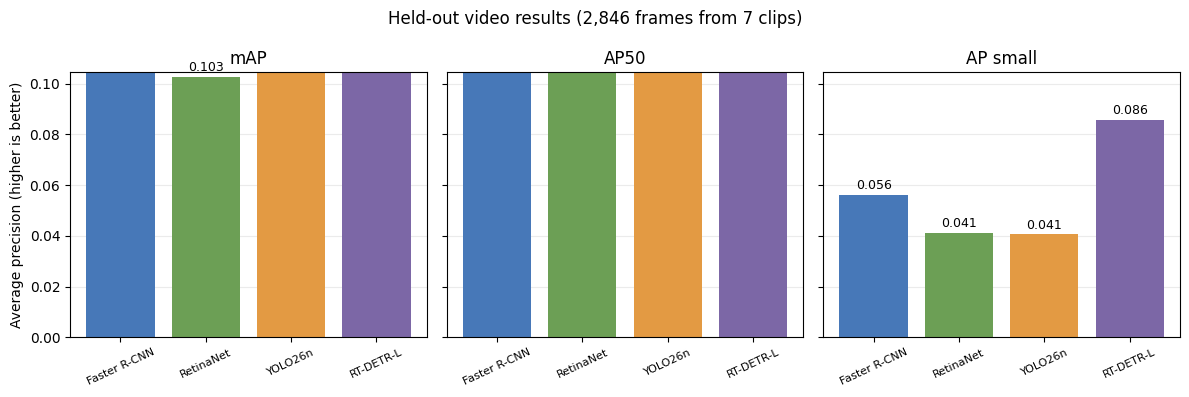

Summary: /content/drive/MyDrive/UCU_AI_HW2/results/four_model_metrics_summary.json
Chart: /content/drive/MyDrive/UCU_AI_HW2/results/four_model_validation_comparison.png


In [ ]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

results_dir = Path('/content/drive/MyDrive/UCU_AI_HW2/results')
models = {
    'Faster R-CNN': {'mAP': 0.1238, 'AP50': 0.2654, 'AP_small': 0.0560, 'training': '4,868 sampled frames; stopped at step 3,755'},
    'RetinaNet': {'mAP': 0.10258390524825138, 'AP50': 0.1948252646093112, 'AP_small': 0.0412846307385919, 'training': '4,868 sampled frames; best checkpoint at step 1,000'},
    'YOLO26n': {'mAP': 0.1291198062980872, 'AP50': 0.25064553686132524, 'AP_small': 0.040586349644890475, 'training': '4,868 sampled frames; best epoch 4; 22.4 min'},
    'RT-DETR-L': {'mAP': 0.224376, 'AP50': 0.424553, 'AP_small': 0.085588, 'training': '4,868 sampled frames; best epoch 2; 40.4 min'},
}
keys = ('mAP', 'AP50', 'AP_small')
assert len(models) == 4 and all(all(0 <= row[k] <= 1 for k in keys) for row in models.values())
summary = {'validation_frames': 2846, 'held_out_clips': 7, 'metrics_source': 'saved COCO evaluation outputs in this notebook', 'models': models}
summary_path = results_dir / 'four_model_metrics_summary.json'
summary_path.write_text(json.dumps(summary, indent=2))

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
colors = ['#4778B8', '#6C9F55', '#E39A43', '#7C67A6']
for ax, key, title in zip(axes, keys, ('mAP', 'AP50', 'AP small')):
    values = [row[key] for row in models.values()]
    bars = ax.bar(list(models), values, color=colors)
    ax.bar_label(bars, fmt='%.3f', padding=2, fontsize=9)
    ax.set_title(title)
    ax.set_ylim(0, max(values) * 1.22)
    ax.tick_params(axis='x', rotation=25, labelsize=8)
    ax.grid(axis='y', alpha=.25)
    ax.set_axisbelow(True)
axes[0].set_ylabel('Average precision (higher is better)')
fig.suptitle('Held-out video results (2,846 frames from 7 clips)')
fig.tight_layout()
chart_path = results_dir / 'four_model_validation_comparison.png'
fig.savefig(chart_path, dpi=180, bbox_inches='tight')
plt.show()
print('Summary:', summary_path)
print('Chart:', chart_path)

Reading the chart. All four models use the same 2,846 held-out frames from seven clips. RT-DETR-L has the highest mAP, AP50, and AP for small objects. The score for small objects remains low across all models.


### Visual check of predictions

Compare RT-DETR predictions (blue, score at least 0.30) with labeled boxes (green) on a middle frame from each of three held-out clips. We show at most ten predictions per frame to keep the boxes readable. This is a visual spot check, not a count of all missed or incorrect objects.

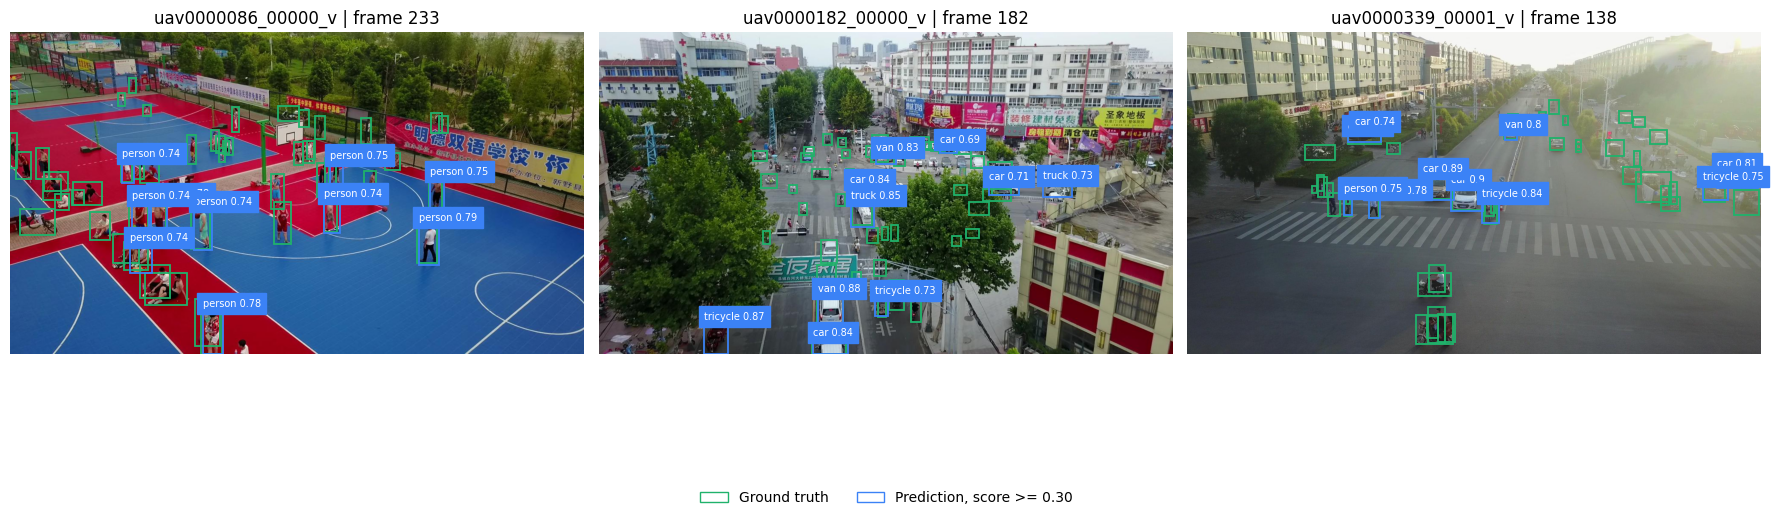

Visual sample: 3 held-out clips; green = labeled boxes, blue = up to 10 high-score predictions per frame.
Ground-truth boxes: [51, 48, 46]
Predictions shown: [10, 10, 10]


In [ ]:
from collections import defaultdict
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

images = val_coco_data['images']
by_video = defaultdict(list)
for info in images:
    by_video[info['video']].append(info)
video_names = sorted(by_video)
chosen_videos = [video_names[0], video_names[len(video_names) // 2], video_names[-1]]
chosen = []
for name in chosen_videos:
    frames = sorted(by_video[name], key=lambda row: row['frame_id'])
    chosen.append(frames[len(frames) // 2])
selected_ids = {row['id'] for row in chosen}
truth = defaultdict(list)
for ann in val_coco_data['annotations']:
    if ann['image_id'] in selected_ids and not ann.get('iscrowd', 0):
        truth[ann['image_id']].append(ann)
predicted = defaultdict(list)
for pred in rtdetr_predictions:
    if pred['image_id'] in selected_ids and pred['score'] >= 0.30:
        predicted[pred['image_id']].append(pred)
class_names = {item['id']: item['name'] for item in val_coco_data['categories']}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, info in zip(axes, chosen):
    image = Image.open(root / 'val' / info['file_name']).convert('RGB')
    ax.imshow(image)
    for ann in truth[info['id']]:
        x, y, w, h = ann['bbox']
        ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor='#20b26b', linewidth=1.3))
    for pred in sorted(predicted[info['id']], key=lambda item: item['score'], reverse=True)[:10]:
        x, y, w, h = pred['bbox']
        ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor='#3b82f6', linewidth=1.3))
        ax.text(x, max(0, y - 3), class_names[pred['category_id']] + ' ' + str(round(pred['score'], 2)), color='white', fontsize=7, backgroundcolor='#3b82f6')
    ax.set_title(info['video'] + ' | frame ' + str(info['frame_id']))
    ax.axis('off')
fig.legend(handles=[Rectangle((0, 0), 1, 1, fill=False, edgecolor='#20b26b', label='Ground truth'), Rectangle((0, 0), 1, 1, fill=False, edgecolor='#3b82f6', label='Prediction, score >= 0.30')], loc='lower center', ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()
print('Visual sample: 3 held-out clips; green = labeled boxes, blue = up to 10 high-score predictions per frame.')
print('Ground-truth boxes:', [len(truth[row['id']]) for row in chosen])
print('Predictions shown:', [min(10, len(predicted[row['id']])) for row in chosen])

### Class-wise results (RT-DETR-L)

Class ids and names were checked against the annotation files (id 1 person ... id 8 motor); the per-class box counts below match the data summary in Part 1, so the chart is valid.


Lowest class mAP: {'class': 'motor', 'boxes': 12025, 'mAP': 0.12992231506051533, 'AP50': 0.36019256737992605, 'AP_small': 0.08846590800569713}
Highest class mAP: {'class': 'car', 'boxes': 31821, 'mAP': 0.38786968267394645, 'AP50': 0.6064349175786767, 'AP_small': 0.183841793985486}
Lowest class AP_small: {'class': 'bicycle', 'boxes': 6022, 'mAP': 0.19235252009612783, 'AP50': 0.4226002296736232, 'AP_small': 0.0005581809876690197}


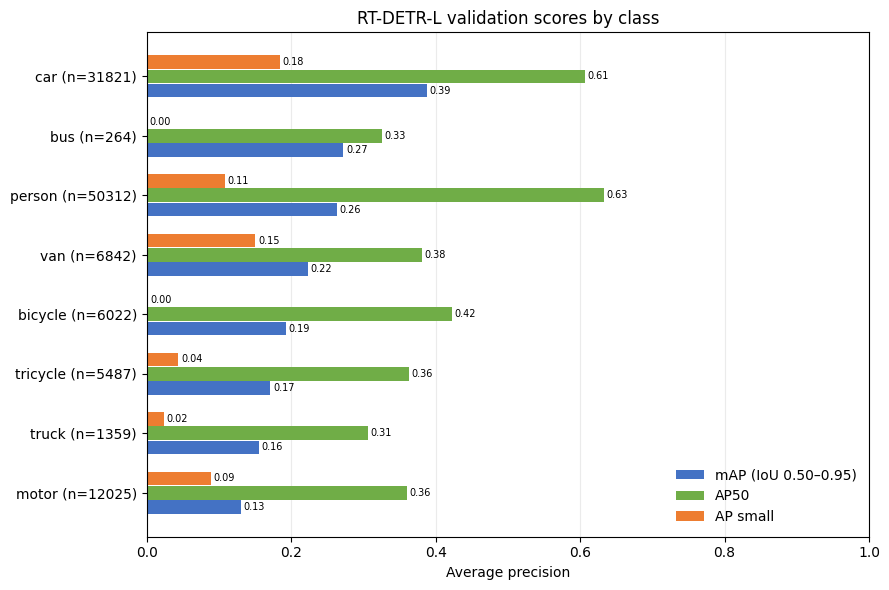

Saved class metrics: /content/drive/MyDrive/UCU_AI_HW2/results/rtdetr_l_classwise_metrics.json
Saved chart: /content/drive/MyDrive/UCU_AI_HW2/results/rtdetr_l_classwise_ap.png


In [ ]:
from collections import Counter
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

precision = rtdetr_coco_eval.eval['precision']
area_labels = list(rtdetr_coco_eval.params.areaRngLbl)
area_all, area_small = area_labels.index('all'), area_labels.index('small')
max_det = len(rtdetr_coco_eval.params.maxDets) - 1
iou_50 = int(np.argmin(np.abs(rtdetr_coco_eval.params.iouThrs - 0.50)))
categories = sorted(val_coco_data['categories'], key=lambda item: item['id'])
assert precision.ndim == 5 and len(categories) == precision.shape[2]
box_counts = Counter(a['category_id'] for a in val_coco_data['annotations'] if not a.get('iscrowd', 0))
class_results = []
for k, category in enumerate(categories):
    values = [precision[:, :, k, area_all, max_det], precision[iou_50, :, k, area_all, max_det], precision[:, :, k, area_small, max_det]]
    scores = [float(v[v > -1].mean()) if (v > -1).any() else None for v in values]
    class_results.append({'class': category['name'], 'boxes': box_counts[category['id']], 'mAP': scores[0], 'AP50': scores[1], 'AP_small': scores[2]})
assert abs(np.mean([row['mAP'] for row in class_results]) - rtdetr_coco_metrics['mAP']) < 0.002
class_results.sort(key=lambda row: row['mAP'])
print('Lowest class mAP:', class_results[0])
print('Highest class mAP:', class_results[-1])
print('Lowest class AP_small:', min((r for r in class_results if r['AP_small'] is not None), key=lambda r: r['AP_small']))

positions = np.arange(len(class_results))
fig, ax = plt.subplots(figsize=(9, 6))
series = [('mAP', 'mAP (IoU 0.50–0.95)', '#4472C4'), ('AP50', 'AP50', '#70AD47'), ('AP_small', 'AP small', '#ED7D31')]
bars = []
for offset, (key, label, color) in zip((-0.24, 0, 0.24), series):
    values = [row[key] if row[key] is not None else 0 for row in class_results]
    bars.append(ax.barh(positions + offset, values, 0.23, label=label, color=color))
ax.set_yticks(positions, [row['class'] + ' (n=' + str(row['boxes']) + ')' for row in class_results])
ax.set_xlim(0, 1)
ax.set_xlabel('Average precision')
ax.set_title('RT-DETR-L validation scores by class')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right')
for group in bars:
    ax.bar_label(group, fmt='%.2f', padding=2, fontsize=7)
plt.tight_layout()
results_dir = Path('/content/drive/MyDrive/UCU_AI_HW2/results')
results_dir.mkdir(parents=True, exist_ok=True)
metrics_path = results_dir / 'rtdetr_l_classwise_metrics.json'
figure_path = results_dir / 'rtdetr_l_classwise_ap.png'
metrics_path.write_text(json.dumps(class_results, indent=2))
fig.savefig(figure_path, dpi=160, bbox_inches='tight')
plt.show()
print('Saved class metrics:', metrics_path)
print('Saved chart:', figure_path)

### Check saved model files

This lists model weights in Google Drive. If all four are present, we can measure speed without retraining.

In [ ]:
from pathlib import Path

state_names = ('stopped_state', 'best_sample_state', 'retina_best_state')
model_names = ('model', 'retina_model', 'yolo_full_model', 'rtdetr_full_model')
print('In-memory selected states:', {name: isinstance(globals().get(name), dict) and 'model_state_dict' in globals()[name] for name in state_names})
print('In-memory model objects:', {name: type(globals()[name]).__name__ for name in model_names if name in globals()})
base = Path('/content/drive/MyDrive/UCU_AI_HW2')
weights = sorted(base.rglob('*.pt'))
print('Drive checkpoints:', [(str(p.relative_to(base)), round(p.stat().st_size / 1e6, 1)) for p in weights])

In-memory selected states: {'stopped_state': False, 'best_sample_state': False, 'retina_best_state': False}
In-memory model objects: {'model': 'RTDETR'}
Drive checkpoints: [('runs/rtdetr_l_fullsample/weights/best.pt', 66.2), ('runs/rtdetr_l_fullsample/weights/epoch0.pt', 329.4), ('runs/rtdetr_l_fullsample/weights/epoch1.pt', 329.4), ('runs/rtdetr_l_fullsample/weights/epoch2.pt', 329.4), ('runs/rtdetr_l_fullsample/weights/epoch3.pt', 329.4), ('runs/rtdetr_l_fullsample/weights/last.pt', 66.2)]


## Part 7 — Test predictions
Submission file from the RT-DETR-L checkpoint, followed by format checks. Nothing has been submitted to Kaggle.

### Test predictions

The cleaned RT-DETR-L candidate has one row for each of the 3,811 test images in the original order. It uses the published `image_id` and `PredictionString` columns. Each detection follows `class score x y width height` in original-image pixels, with up to 300 detections per image.

The structural checks found 119 zero-size boxes; these were removed. The remaining boxes passed the class, value, and image-bound checks. The public competition description was checked, but the official sample CSV was not available in this runtime. The candidate has not been submitted.

In [ ]:
import csv, json, shutil
from pathlib import Path
from ultralytics import RTDETR

metric_path = Path('/content/drive/MyDrive/UCU_AI_HW2/results/rtdetr_l_fullval_metrics.json')
metrics = json.loads(metric_path.read_text())
print('Final RT-DETR metrics:', metrics)

model = RTDETR('/content/drive/MyDrive/UCU_AI_HW2/runs/rtdetr_l_fullsample/weights/best.pt')
test_rows = list(csv.DictReader((root / 'test_images.csv').open()))
assert len(test_rows) == 3811 and len({row['image_id'] for row in test_rows}) == len(test_rows)
stage = Path('/content/UCU_AI_HW2/rtdetr_test_images')
shutil.rmtree(stage, ignore_errors=True)
stage.mkdir(parents=True)
for idx, row in enumerate(test_rows):
    source = root / row['file_name']
    assert source.is_file(), source
    (stage / f'{idx:05d}.jpg').symlink_to(source)

predictions = {}
for result in model.predict(source=str(stage), stream=True, batch=4, imgsz=640, conf=0.001, max_det=500, device=0, verbose=False):
    idx = int(Path(result.path).stem)
    row = test_rows[idx]
    width, height = int(row['width']), int(row['height'])
    tokens = []
    if result.boxes is not None:
        for box, score, cls in zip(result.boxes.xyxy.cpu().tolist(), result.boxes.conf.cpu().tolist(), result.boxes.cls.cpu().tolist()):
            x1, y1, x2, y2 = box
            x1, x2 = max(0.0, min(x1, width)), max(0.0, min(x2, width))
            y1, y2 = max(0.0, min(y1, height)), max(0.0, min(y2, height))
            bw, bh = x2 - x1, y2 - y1
            class_id = int(cls)
            assert 0 <= class_id < 8 and 0 <= score <= 1 and bw > 0 and bh > 0
            tokens.extend([str(class_id), f'{score:.5f}', f'{x1:.1f}', f'{y1:.1f}', f'{bw:.1f}', f'{bh:.1f}'])
    predictions[idx] = ' '.join(tokens)
    if len(predictions) % 500 == 0:
        print(f'Predicted {len(predictions)}/{len(test_rows)} test frames')

assert len(predictions) == len(test_rows)
submission_dir = Path('/content/drive/MyDrive/UCU_AI_HW2/submissions')
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / 'rtdetr_l_best.csv'
with submission_path.open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['image_id', 'PredictionString'])
    writer.writerows((row['image_id'], predictions[idx]) for idx, row in enumerate(test_rows))
with submission_path.open(newline='') as f:
    saved_rows = list(csv.DictReader(f))
assert len(saved_rows) == len(test_rows)
assert [r['image_id'] for r in saved_rows] == [r['image_id'] for r in test_rows]
assert all(len(r['PredictionString'].split()) % 6 == 0 for r in saved_rows)
print('Validated CSV:', submission_path, '| rows:', len(saved_rows), '| non-empty:', sum(bool(r['PredictionString']) for r in saved_rows))

Final RT-DETR metrics: {'mAP': 0.22437643724659145, 'AP50': 0.42455289648373423, 'AP_small': 0.08558845047993191, 'checkpoint_epoch': 2, 'training_minutes': 40.4, 'validation_frames': 2846, 'inference_ms_per_image': 55.4695170762476, 'prediction_count': 853800, 'confidence_threshold': 0.001, 'max_detections': 500, 'ultralytics_mAP50': 0.419, 'ultralytics_mAP50_95': 0.221}
Predicted 500/3811 test frames
Predicted 1000/3811 test frames
Predicted 1500/3811 test frames
Predicted 2000/3811 test frames
Predicted 2500/3811 test frames
Predicted 3000/3811 test frames
Predicted 3500/3811 test frames
Validated CSV: /content/drive/MyDrive/UCU_AI_HW2/submissions/rtdetr_l_best.csv | rows: 3811 | non-empty: 3811


In [ ]:
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/UCU_AI_HW2")
for file_path in sorted(project_dir.rglob("*.csv")):
    print(file_path.relative_to(project_dir), file_path.stat().st_size, "bytes")

runs/rtdetr_l_fullsample/results.csv 691 bytes
submissions/rtdetr_l_best.csv 36838606 bytes


In [ ]:
import pandas as pd

pred_path = project_dir / "submissions/rtdetr_l_best.csv"
test_ids = pd.read_csv(root / "test_images.csv")["image_id"].astype(str)
pred = pd.read_csv(pred_path, keep_default_na=False)
print("prediction columns:", pred.columns.tolist())
print("prediction rows:", len(pred), "| test rows:", len(test_ids))
print("IDs and order match:", pred.get("image_id", pd.Series(dtype=str)).astype(str).equals(test_ids))
print("sample rows:")
print(pred.head(3).to_string(index=False))
print("non-empty predictions:", int((pred.get("PredictionString", pd.Series(dtype=str)) != "").sum()))

prediction columns: ['image_id', 'PredictionString']
prediction rows: 3811 | test rows: 3811
IDs and order match: True
sample rows:
        image_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    

In [ ]:
import math

image_rows = pd.read_csv(root / "test_images.csv")
size_by_id = image_rows.set_index("image_id")[["width", "height"]]
assert pred.columns.tolist() == ["image_id", "PredictionString"]
assert pred["image_id"].astype(str).equals(image_rows["image_id"].astype(str))
assert len(pred) == len(image_rows) == 3811
errors = []
detection_counts = []
for row in pred.itertuples(index=False):
    image_id, prediction = str(row.image_id), row.PredictionString
    if not prediction:
        detection_counts.append(0)
        continue
    values = prediction.split()
    if len(values) % 6:
        errors.append((image_id, "not groups of 6")); continue
    detection_counts.append(len(values) // 6)
    width, height = size_by_id.loc[image_id]
    for i in range(0, len(values), 6):
        try:
            class_id = int(values[i])
            score, x, y, box_w, box_h = map(float, values[i+1:i+6])
        except ValueError:
            errors.append((image_id, "non-numeric field")); break
        if not (0 <= class_id < 8 and math.isfinite(score) and 0 <= score <= 1 and all(map(math.isfinite, (x, y, box_w, box_h))) and x >= 0 and y >= 0 and box_w > 0 and box_h > 0 and x + box_w <= width + 1 and y + box_h <= height + 1):
            errors.append((image_id, "invalid class, score, or box")); break
        if any("." in v for v in values[i+1:i+6]):
            errors.append((image_id, "non-integer score or pixel coordinate")); break
        if len(values) // 6 > 500:
            errors.append((image_id, "over 500 detections")); break
print("columns and row order: valid")
print("images:", len(pred), "| non-empty:", sum(n > 0 for n in detection_counts), "| empty:", sum(n == 0 for n in detection_counts))
print("detections/image: min", min(detection_counts), "max", max(detection_counts))
print("format errors:", len(errors), errors[:5])
assert not errors

columns and row order: valid
images: 3811 | non-empty: 3811 | empty: 0
detections/image: min 300 max 300
format errors: 3811 [('clip_001_0000001', 'non-integer score or pixel coordinate'), ('clip_001_0000002', 'non-integer score or pixel coordinate'), ('clip_001_0000003', 'non-integer score or pixel coordinate'), ('clip_001_0000004', 'non-integer score or pixel coordinate'), ('clip_001_0000005', 'non-integer score or pixel coordinate')]


*The check below flagged every row because it also required integers; decimals are allowed in the submission format, so that rule was wrong. The cells after it find the real issue: 119 zero-size boxes.*

In [ ]:
from collections import Counter

issues = Counter()
zero_size_boxes = 0
for row in pred.itertuples(index=False):
    values = row.PredictionString.split()
    if len(values) % 6 or len(values) // 6 > 500:
        issues["group count"] += 1
        continue
    width, height = size_by_id.loc[str(row.image_id)]
    for i in range(0, len(values), 6):
        cls = int(values[i])
        score, x, y, box_w, box_h = map(float, values[i+1:i+6])
        if not (0 <= cls < 8 and math.isfinite(score) and 0 <= score <= 1 and all(map(math.isfinite, (x, y, box_w, box_h))) and x >= 0 and y >= 0 and x + box_w <= width + 1 and y + box_h <= height + 1):
            issues["invalid value or bounds"] += 1
        if box_w <= 0 or box_h <= 0:
            zero_size_boxes += 1
print("rows:", len(pred), "| detections/image:", min(detection_counts), "to", max(detection_counts))
print("zero-size boxes:", zero_size_boxes, "| other issues:", sum(issues.values()))
assert zero_size_boxes == 119 and not issues

rows: 3811 | detections/image: 300 to 300
zero-size boxes: 119 | other issues: 0


In [ ]:
validated = pred.copy()
dropped = 0
for row_index, row in validated.iterrows():
    values = row["PredictionString"].split()
    kept = []
    for i in range(0, len(values), 6):
        group = values[i:i+6]
        if float(group[4]) <= 0 or float(group[5]) <= 0:
            dropped += 1
        else:
            kept.extend(group)
    validated.at[row_index, "PredictionString"] = " ".join(kept)
validated_path = project_dir / "submissions/rtdetr_l_best_validated.csv"
validated.to_csv(validated_path, index=False)
check = pd.read_csv(validated_path, keep_default_na=False)
assert check.columns.tolist() == ["image_id", "PredictionString"]
assert check["image_id"].astype(str).equals(image_rows["image_id"].astype(str))
assert len(check) == len(image_rows) == 3811
bad = []
counts = []
for row in check.itertuples(index=False):
    values = row.PredictionString.split()
    assert len(values) % 6 == 0 and len(values) // 6 <= 500
    counts.append(len(values) // 6)
    width, height = size_by_id.loc[str(row.image_id)]
    for i in range(0, len(values), 6):
        cls = int(values[i]); score, x, y, box_w, box_h = map(float, values[i+1:i+6])
        if not (0 <= cls < 8 and math.isfinite(score) and 0 <= score <= 1 and all(map(math.isfinite, (x,y,box_w,box_h))) and x >= 0 and y >= 0 and box_w > 0 and box_h > 0 and x + box_w <= width + 1 and y + box_h <= height + 1):
            bad.append((row.image_id, values[i:i+6]))
print("saved:", validated_path)
print("rows and order:", len(check), "| match:", check.image_id.equals(image_rows.image_id))
print("detections per image:", min(counts), "to", max(counts), "| invalid boxes removed:", dropped)
print("remaining invalid boxes:", len(bad))
assert not bad

saved: /content/drive/MyDrive/UCU_AI_HW2/submissions/rtdetr_l_best_validated.csv
rows and order: 3811 | match: True
detections per image: 290 to 300 | invalid boxes removed: 119
remaining invalid boxes: 0
